#**Imports**

In [919]:
from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, pairwise_distances
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "colab"  # interactive 3D in Colab
sns.set(style="whitegrid", context="notebook")

#**1. Data Understanding & Exploration**

**Load and examine dataset structure**

In [920]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [921]:
cd /content/drive/MyDrive/Colab Notebooks/DA

/content/drive/MyDrive/Colab Notebooks/DA


In [922]:
df = pd.read_csv("Customer Data.csv")

In [923]:
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [924]:
df.tail()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.50,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.00,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.25,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.25,6
8949,C19190,372.708075,0.666667,1093.25,1093.25,0.00,127.040008,0.666667,0.666667,0.000000,0.333333,2,23,1200.0,63.165404,88.288956,0.00,6


In [925]:
df.shape

(8950, 18)

**Identify data types and basic statistics**

In [926]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [927]:
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


**Check duplicates**

In [928]:
df.duplicated().sum()

np.int64(0)

**Detect missing values and outliers**

In [929]:
print("\nMissing values per column (counts):")
print(df.isna().sum().sort_values(ascending=False))


Missing values per column (counts):
MINIMUM_PAYMENTS                    313
CREDIT_LIMIT                          1
BALANCE                               0
CUST_ID                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
PURCHASES_INSTALLMENTS_FREQUENCY      0
ONEOFF_PURCHASES_FREQUENCY            0
CASH_ADVANCE_TRX                      0
CASH_ADVANCE_FREQUENCY                0
PURCHASES_TRX                         0
PAYMENTS                              0
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64


In [930]:
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1

# Boolean mask of outliers
outlier_mask = (df[num_cols] < (Q1 - 1.5 * IQR)) | (df[num_cols] > (Q3 + 1.5 * IQR))

# Count outliers per column
outliers_per_column = outlier_mask.sum()
outliers_per_column

,0
BALANCE,695
BALANCE_FREQUENCY,1493
PURCHASES,808
ONEOFF_PURCHASES,1013
INSTALLMENTS_PURCHASES,867
CASH_ADVANCE,1030
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,782
PURCHASES_INSTALLMENTS_FREQUENCY,0
CASH_ADVANCE_FREQUENCY,525


#**2. Data Preprocessing & Cleaning**

Drop irrelevant columns

In [931]:
df = df.drop(columns=["CUST_ID"])
df.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


**Handle missing values appropriately**

In [932]:
#impute missing values
df['MINIMUM_PAYMENTS'] = df['MINIMUM_PAYMENTS'].fillna(df['MINIMUM_PAYMENTS'].median())
df['CREDIT_LIMIT'] = df['CREDIT_LIMIT'].fillna(df['CREDIT_LIMIT'].median())

# Confirm no missing values remain
print("Missing values after imputation:")
print(df.isna().sum())



Missing values after imputation:
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64


We imputed missing values in MINIMUM_PAYMENTS and CREDIT_LIMIT using the median because both are numeric financial columns with a few missing entries. The median is robust to outliers and preserves the natural distribution of the data, unlike the mean, which could be skewed by extreme values. Dropping rows or filling with zero could bias the clustering or misrepresent customer behavior. This approach ensures that all customers remain in the dataset without introducing artificial distortions, which is important for generating meaningful and interpretable segments.

**Address outliers using suitable methods**

In [933]:
# Function to cap outliers
def cap_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return series.clip(lower, upper)

# Apply to numeric columns except TENURE and PRC_FULL_PAYMENT
for col in num_cols:
    if col not in ['TENURE', 'PRC_FULL_PAYMENT']:
        df[col] = cap_outliers(df[col])

In [934]:
# Check min and max after capping
print("Min and max values after capping:")
display(df[num_cols].agg(['min', 'max']))

# Recalculate outliers per column
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (df[num_cols] < (Q1 - 1.5 * IQR)) | (df[num_cols] > (Q3 + 1.5 * IQR))
outliers_per_column = outlier_mask.sum()
print("\nNumber of outliers per column after capping:")
print(outliers_per_column)

Min and max values after capping:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
min,0.000000,0.722223,0.0000,0.0000,0.00000,0.000000,0.0,0.00,0.0,0.000000,0,0,50.0,0.000000,0.019163,0.0,6
max,4942.927215,1.000000,2715.8725,1443.5125,1171.59375,2784.552848,1.0,0.75,1.0,0.555555,10,41,13850.0,4177.921543,1715.497271,1.0,12



Number of outliers per column after capping:
BALANCE                                0
BALANCE_FREQUENCY                      0
PURCHASES                              0
ONEOFF_PURCHASES                       0
INSTALLMENTS_PURCHASES                 0
CASH_ADVANCE                           0
PURCHASES_FREQUENCY                    0
ONEOFF_PURCHASES_FREQUENCY             0
PURCHASES_INSTALLMENTS_FREQUENCY       0
CASH_ADVANCE_FREQUENCY                 0
CASH_ADVANCE_TRX                       0
PURCHASES_TRX                          0
CREDIT_LIMIT                           0
PAYMENTS                               0
MINIMUM_PAYMENTS                       0
PRC_FULL_PAYMENT                    1474
TENURE                              1366
dtype: int64


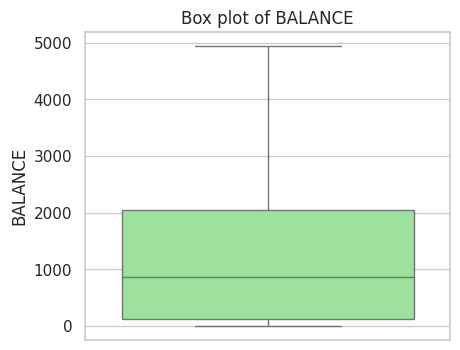

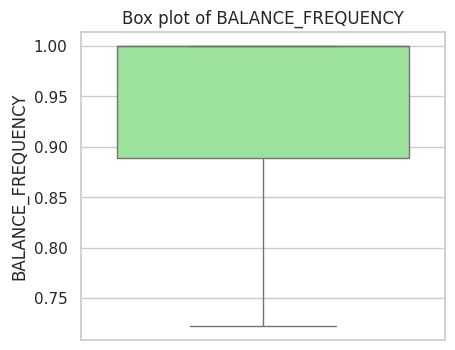

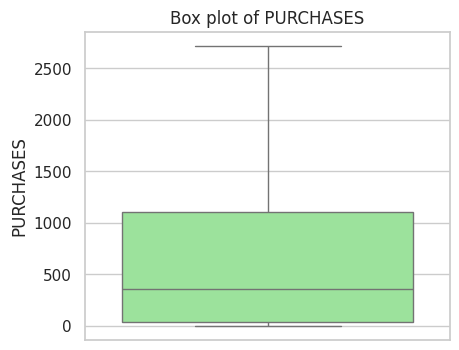

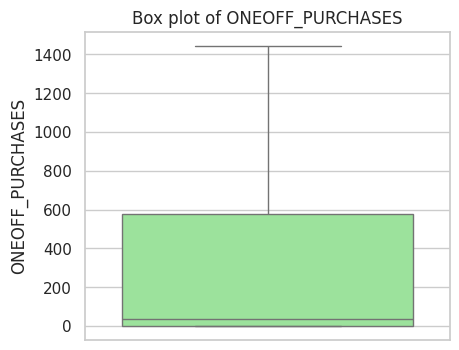

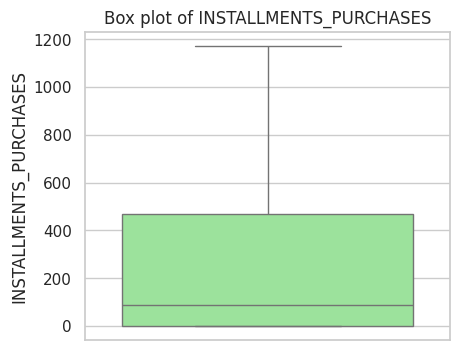

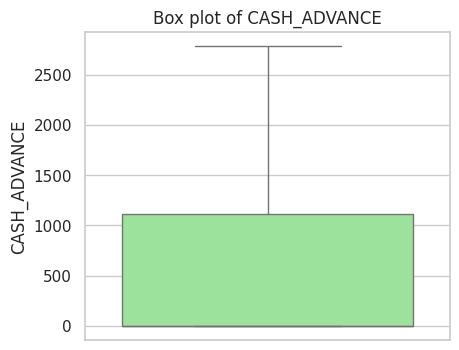

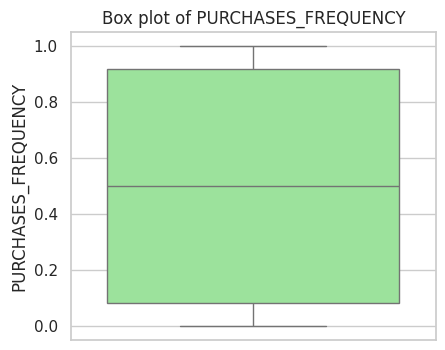

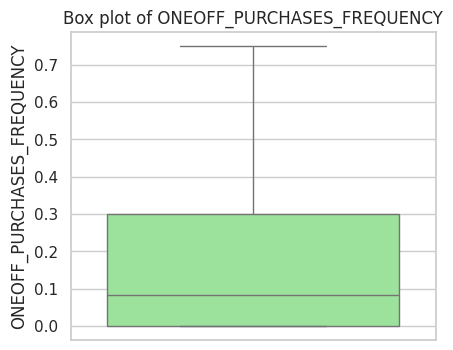

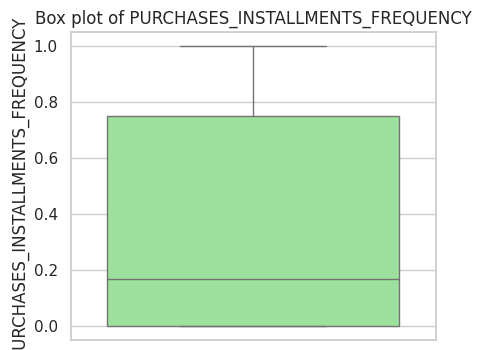

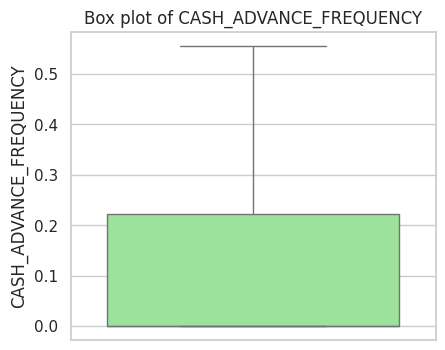

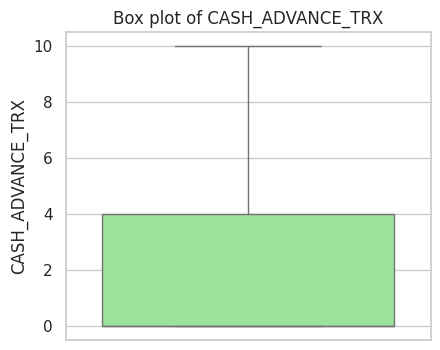

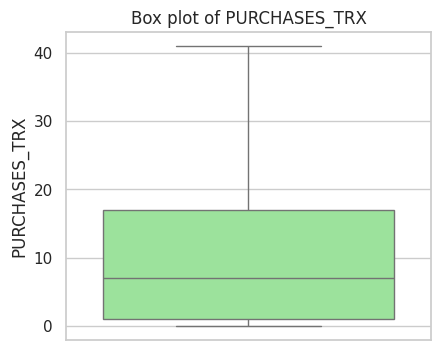

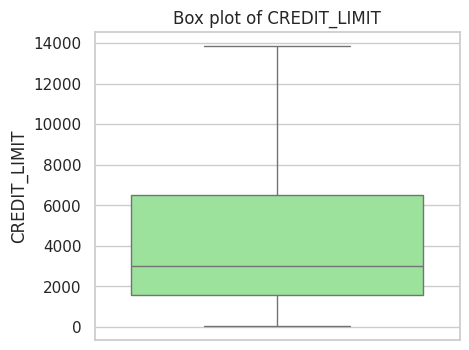

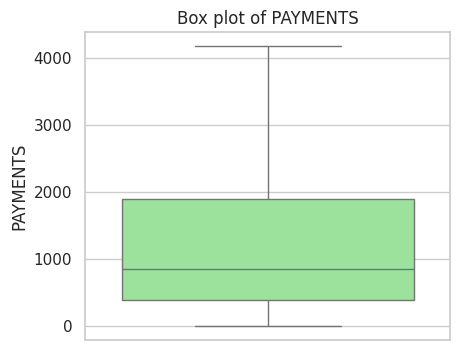

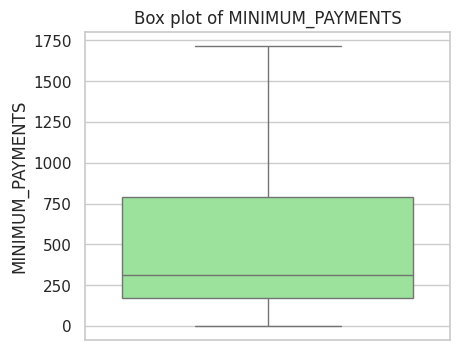

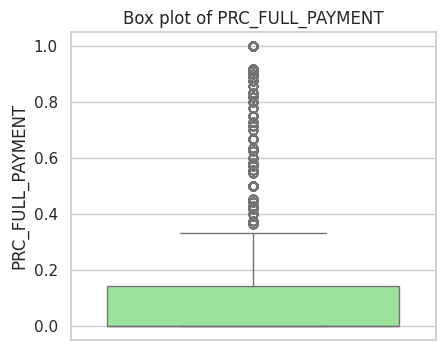

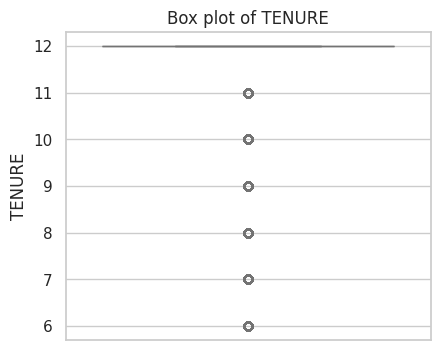

In [935]:
for col in num_cols:
    plt.figure(figsize=(16,4))
    plt.subplot(1,3,2)
    sns.boxplot(y=df[col], color='lightgreen')
    plt.title(f'Box plot of {col}')

We use the capping (Winsorization) method to limit extreme values in numeric features, replacing any values beyond the 1.5×IQR range with the nearest bound. This prevents outliers from disproportionately influencing distance-based clustering algorithms like KMeans, ensuring more meaningful and stable clusters. We exclude columns like TENURE and PRC_FULL_PAYMENT because their values are naturally bounded and categorical-like (e.g., TENURE ranges from 6 to 12 months, PRC_FULL_PAYMENT is a proportion 0–1), so capping would distort their true distribution and misrepresent customer behavior.

**Numeric Distribution & Skewness Analysis**

In [936]:
# Select numeric columns (exclude CUST_ID)
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Summary statistics
print("Numeric summary (describe):")
display(df[num_cols].describe().T)

# Skewness (to spot heavy-tailed distributions)
print("\nSkewness for numeric columns:")
skewness = df[num_cols].skew().sort_values(ascending=False)
print(skewness)

Numeric summary (describe):


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1390.508973,1537.538479,0.000000,128.281915,873.385231,2054.140036,4942.927215
BALANCE_FREQUENCY,8950.0,0.931587,0.110984,0.722223,0.888889,1.000000,1.000000,1.000000
PURCHASES,8950.0,737.149330,879.534788,0.000000,39.635000,361.280000,1110.130000,2715.872500
ONEOFF_PURCHASES,8950.0,354.358139,511.823289,0.000000,0.000000,38.000000,577.405000,1443.512500
INSTALLMENTS_PURCHASES,8950.0,295.546214,396.181546,0.000000,0.000000,89.000000,468.637500,1171.593750
CASH_ADVANCE,8950.0,672.468924,998.514970,0.000000,0.000000,0.000000,1113.821139,2784.552848
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.000000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.184773,0.255668,0.000000,0.000000,0.083333,0.300000,0.750000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.000000
CASH_ADVANCE_FREQUENCY,8950.0,0.126061,0.172676,0.000000,0.000000,0.000000,0.222222,0.555555



Skewness for numeric columns:
PRC_FULL_PAYMENT                    1.942820
CASH_ADVANCE_TRX                    1.282306
CASH_ADVANCE_FREQUENCY              1.273882
ONEOFF_PURCHASES_FREQUENCY          1.250964
CASH_ADVANCE                        1.241773
ONEOFF_PURCHASES                    1.237216
INSTALLMENTS_PURCHASES              1.217388
PURCHASES                           1.206380
MINIMUM_PAYMENTS                    1.172922
BALANCE                             1.166703
PURCHASES_TRX                       1.139781
PAYMENTS                            1.130056
CREDIT_LIMIT                        1.102331
PURCHASES_INSTALLMENTS_FREQUENCY    0.509201
PURCHASES_FREQUENCY                 0.060164
BALANCE_FREQUENCY                  -1.172978
TENURE                             -2.943017
dtype: float64


This summary shows the distribution of each numeric feature in the dataset. For most spending and cash advance-related features (e.g., BALANCE, PURCHASES, CASH_ADVANCE), the mean is higher than the median, indicating a right-skewed distribution, which is confirmed by the positive skewness values (>1 for many columns). Features like BALANCE_FREQUENCY and TENURE are slightly or negatively skewed, meaning their values are more concentrated or have a few lower outliers. Many features also have a minimum of 0, showing that some customers did not engage in those activities. The high skewness in some columns highlights the presence of extreme values, which can disproportionately influence distance-based clustering algorithms, making transformations like log1p useful before clustering.

In [937]:
# Select features with positive skew above ~1
skewed_features = ['PRC_FULL_PAYMENT', 'CASH_ADVANCE_FREQUENCY',
                   'ONEOFF_PURCHASES_FREQUENCY', 'BALANCE',
                   'PURCHASES_TRX', 'CREDIT_LIMIT']

# Apply log1p transformation to reduce skewness
df[skewed_features] = df[skewed_features].apply(lambda x: np.log1p(x))

# Check skewness after transformation
skewness_after = df[skewed_features].skew()
print("Skewness after log1p transformation:")
print(skewness_after)

Skewness after log1p transformation:
PRC_FULL_PAYMENT              1.746046
CASH_ADVANCE_FREQUENCY        1.113911
ONEOFF_PURCHASES_FREQUENCY    1.091750
BALANCE                      -0.936687
PURCHASES_TRX                -0.180048
CREDIT_LIMIT                 -0.153848
dtype: float64


After applying the log1p transformation, most features show reduced skewness, indicating a more symmetric distribution. Features that were highly right-skewed, like BALANCE, PURCHASES_TRX, and CREDIT_LIMIT, now have slight negative skew (-0.937, -0.180, and -0.154 respectively), making them closer to a normal distribution. However, features with inherently sparse or zero-heavy distributions, such as PRC_FULL_PAYMENT (1.746), CASH_ADVANCE_FREQUENCY (1.114), and ONEOFF_PURCHASES_FREQUENCY (1.092), remain positively skewed, though less extreme than before. Overall, the transformation has reduced the impact of extreme values, improving the suitability of these variables for distance-based analyses like clustering.

**Normalize/standardize numerical features**

In [938]:
num_cols = df.select_dtypes(include='number').columns

scaler = StandardScaler()

df_scaled = df.copy()
df_scaled[num_cols] = scaler.fit_transform(df[num_cols])

df_scaled.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-1.212955,-1.021875,-0.729687,-0.692383,-0.505216,-0.673507,-0.806490,-0.764448,-0.707313,-0.761744,-0.697293,-0.579330,-1.457620,-0.899859,-0.784078,-0.556368,0.36068
1,0.978578,-0.202708,-0.838160,-0.692383,-0.746029,2.115343,-1.221758,-0.764448,-0.916995,0.810318,0.473089,-1.425766,0.942222,2.165375,0.968887,0.391958,0.36068
2,0.852502,0.616459,0.040957,0.818320,-0.746029,-0.673507,1.269843,2.103072,-0.916995,-0.761744,-0.697293,0.550423,1.027335,-0.569653,0.132544,-0.556368,0.36068
3,0.648684,-1.886552,0.866246,2.128108,-0.746029,-0.467401,-1.014125,-0.354304,-0.916995,-0.197840,-0.404697,-0.891724,1.027335,-1.058417,-0.459290,-0.556368,0.36068
4,0.289156,0.616459,-0.819967,-0.661121,-0.746029,-0.673507,-1.014125,-0.354304,-0.916995,-0.761744,-0.697293,-0.891724,-1.232874,-0.525443,-0.586234,-0.556368,0.36068


#**3. Exploratory Data Analysis (EDA)**

#**a. Univariate Analysis**

**Central Tendencies**

In [939]:
# Display count, mean, std, min, 25%, 50%, 75%, max
display(df[num_cols].describe())

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000
mean,6.135543,0.931587,737.149330,354.358139,295.546214,672.468924,0.490351,0.149187,0.364437,0.108124,2.383128,1.850540,8.090145,1347.084165,556.752385,0.117730,11.517318
std,1.978947,0.110984,879.534788,511.823289,396.181546,998.514970,0.401371,0.195168,0.397448,0.141951,3.417878,1.298000,0.810538,1272.806272,532.174180,0.211617,1.338331
min,0.000000,0.722223,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.931826,0.000000,0.019163,0.000000,6.000000
25%,4.861995,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,0.693147,7.378384,383.276166,170.857654,0.000000,12.000000
50%,6.773521,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.080042,0.166667,0.000000,0.000000,2.079442,8.006701,856.901546,312.343947,0.000000,12.000000
75%,7.628099,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.262364,0.750000,0.200671,4.000000,2.890372,8.779711,1901.134317,788.713501,0.133531,12.000000
max,8.505915,1.000000,2715.872500,1443.512500,1171.593750,2784.552848,1.000000,0.559616,1.000000,0.441832,10.000000,3.737670,9.536113,4177.921543,1715.497271,0.693147,12.000000


**Distribution, Box, and Violin Plots**

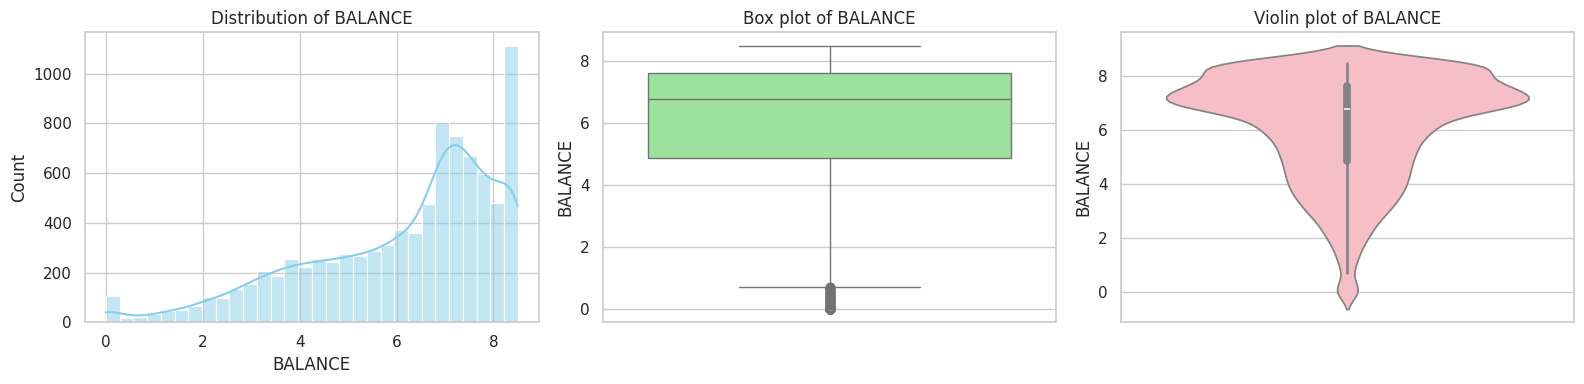

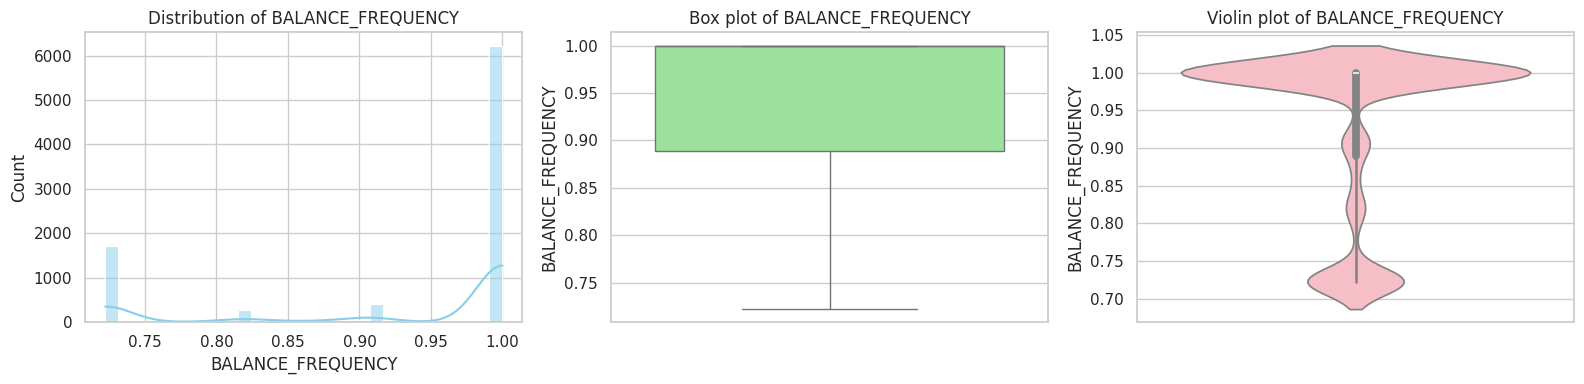

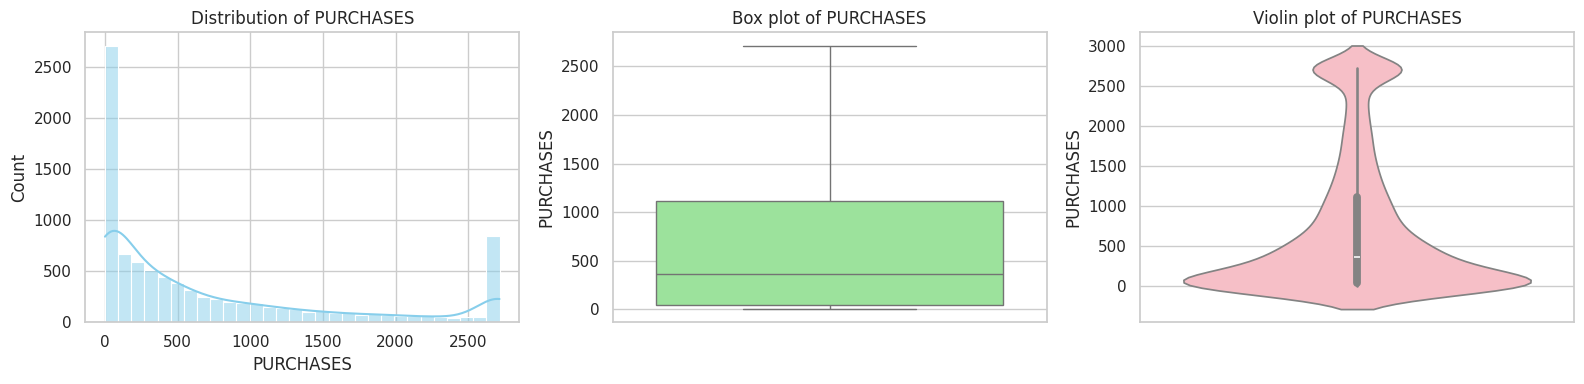

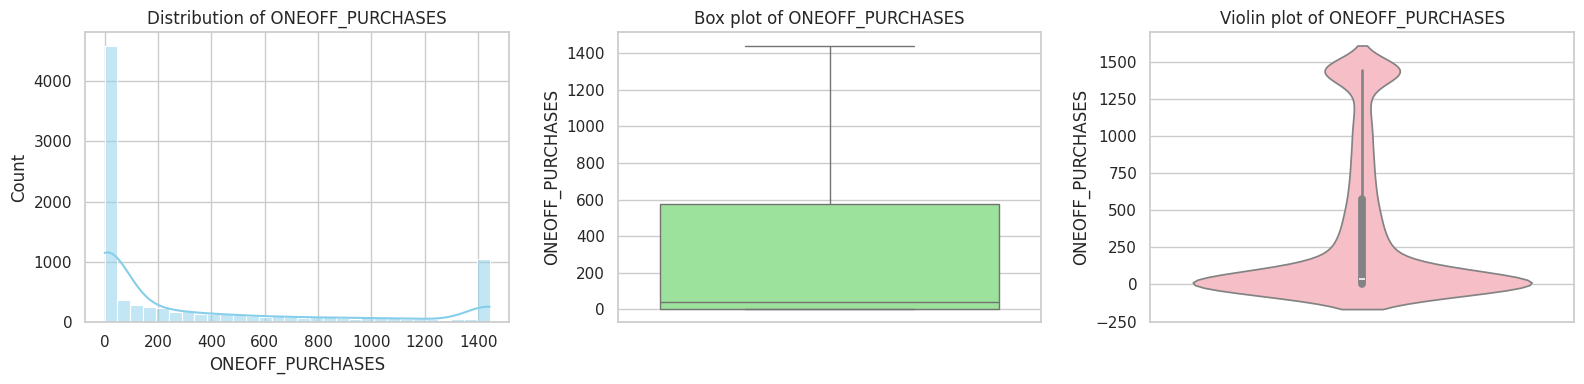

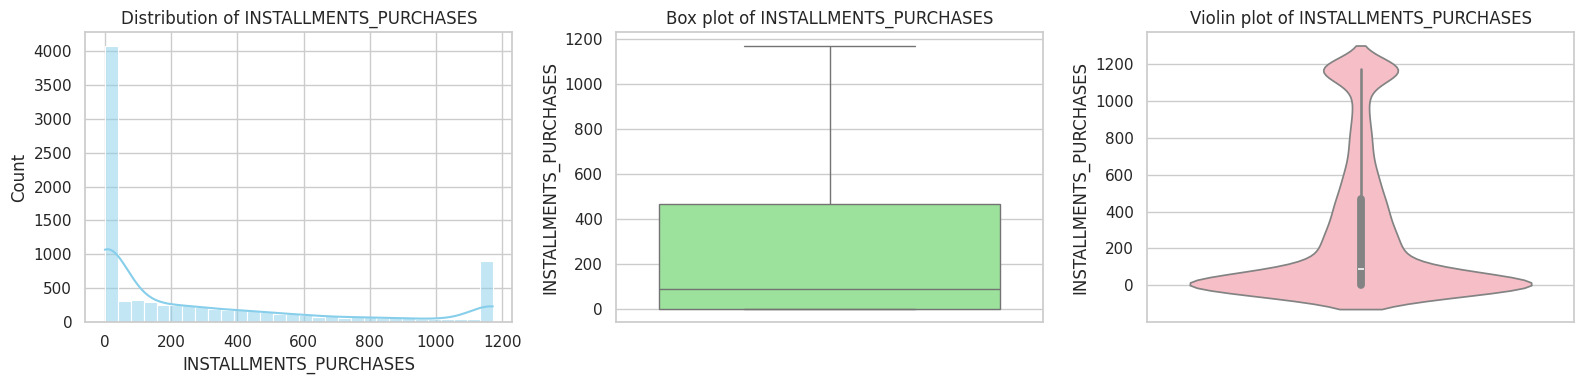

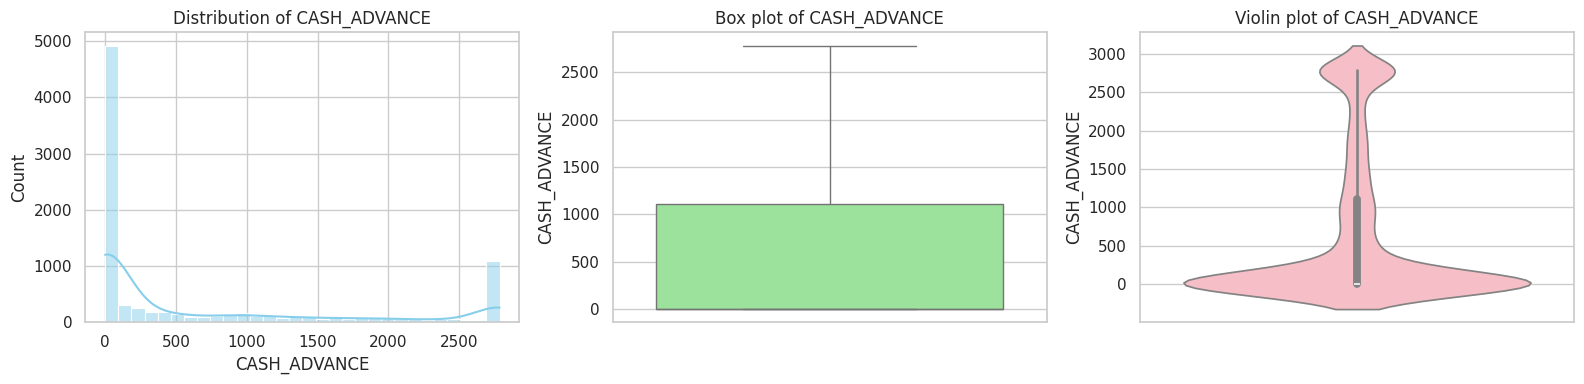

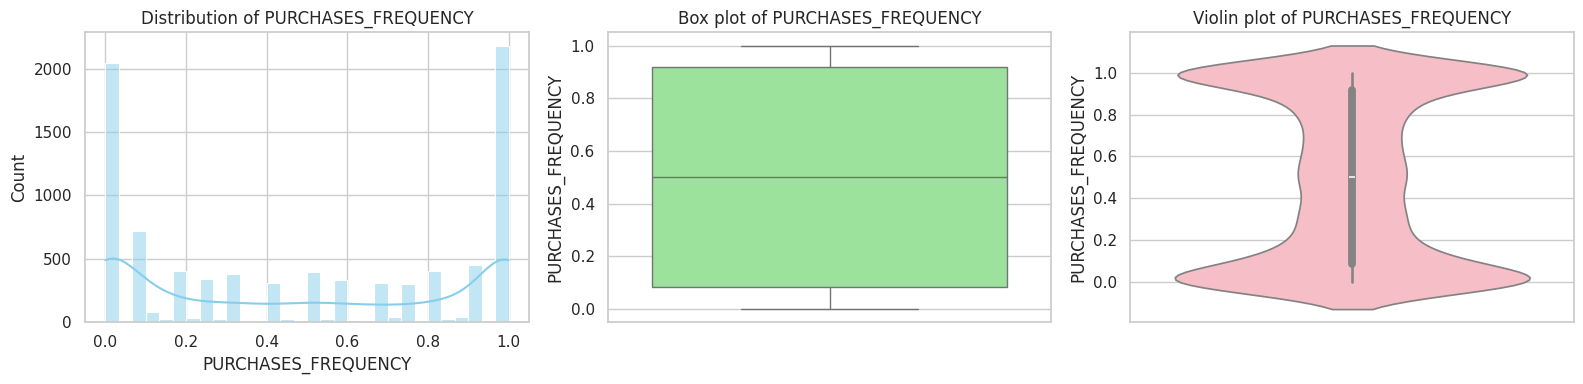

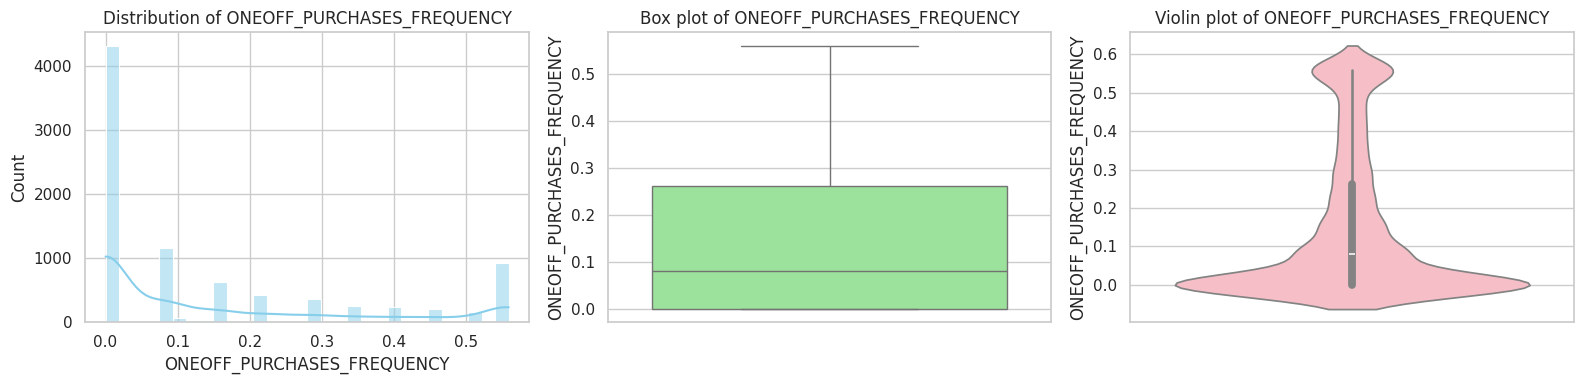

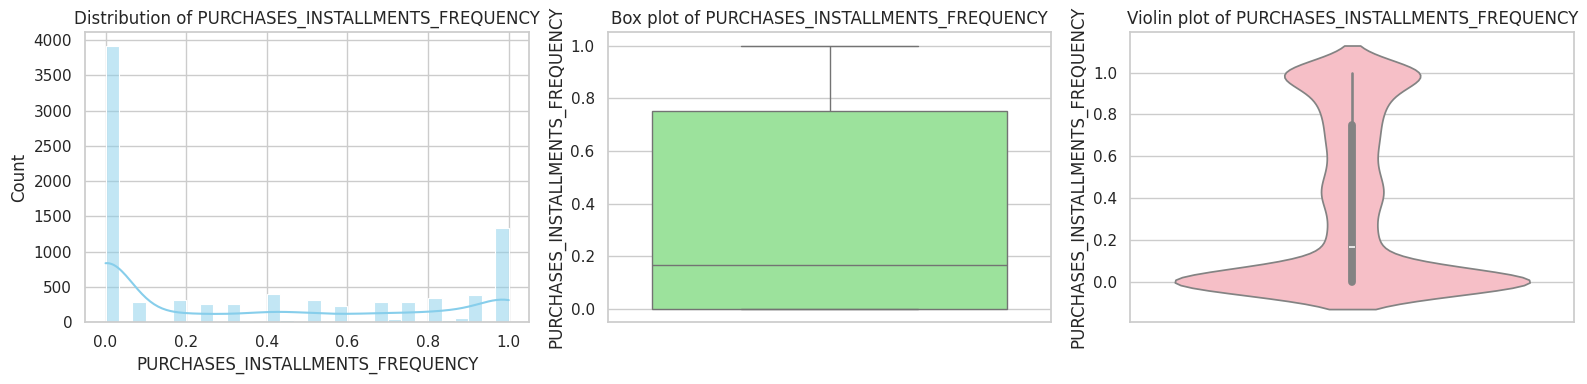

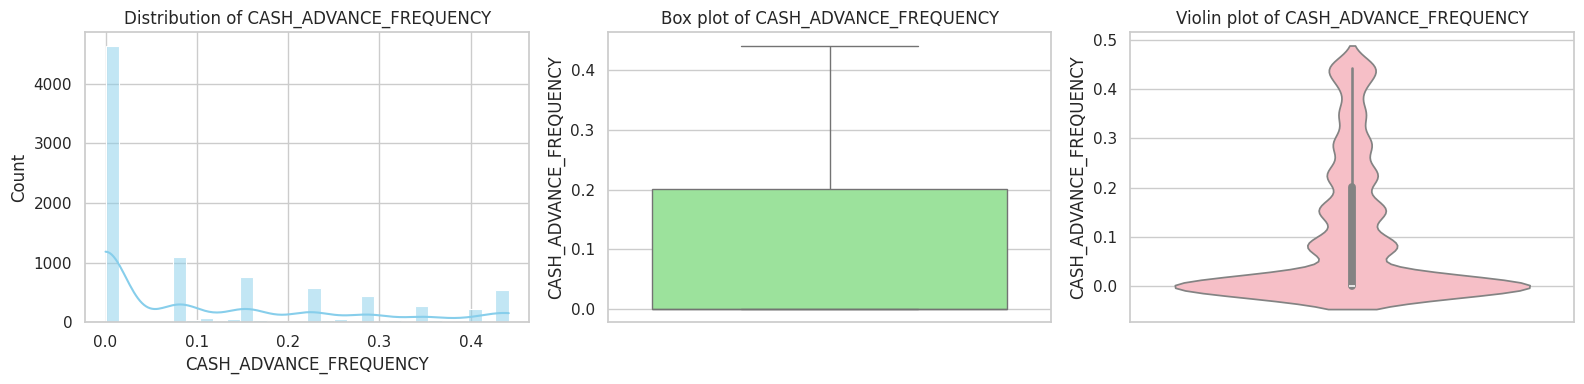

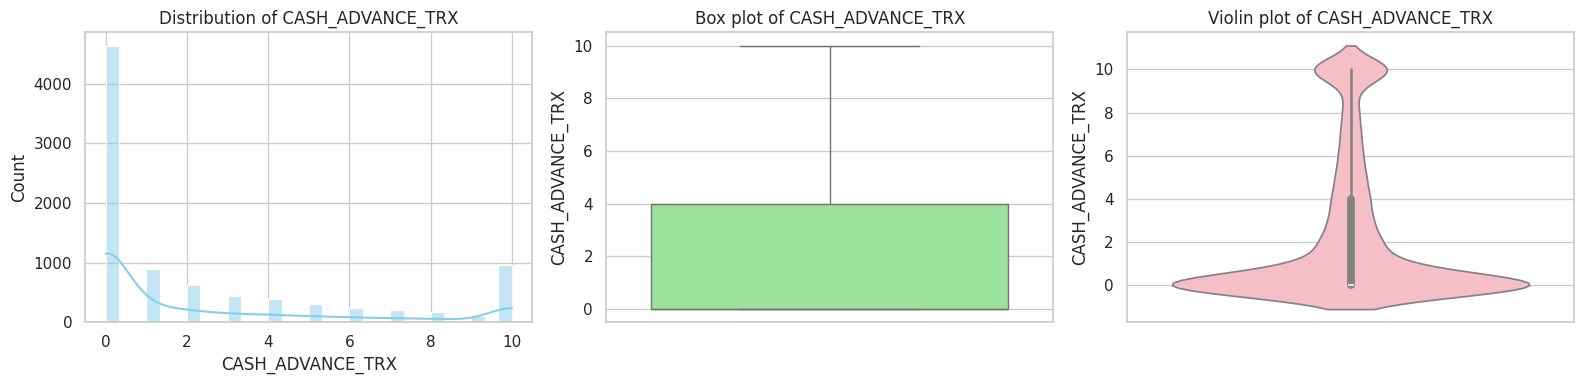

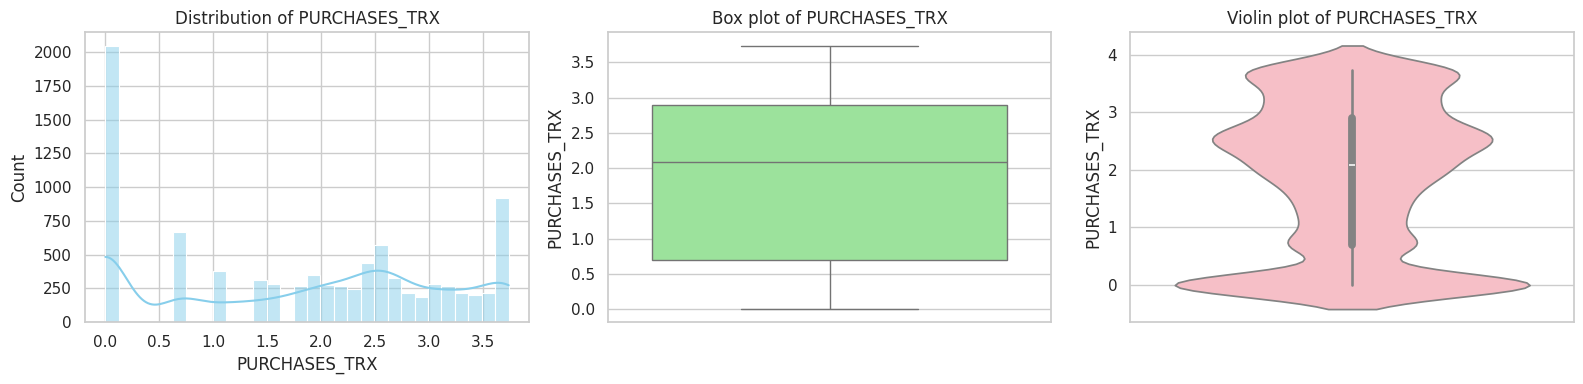

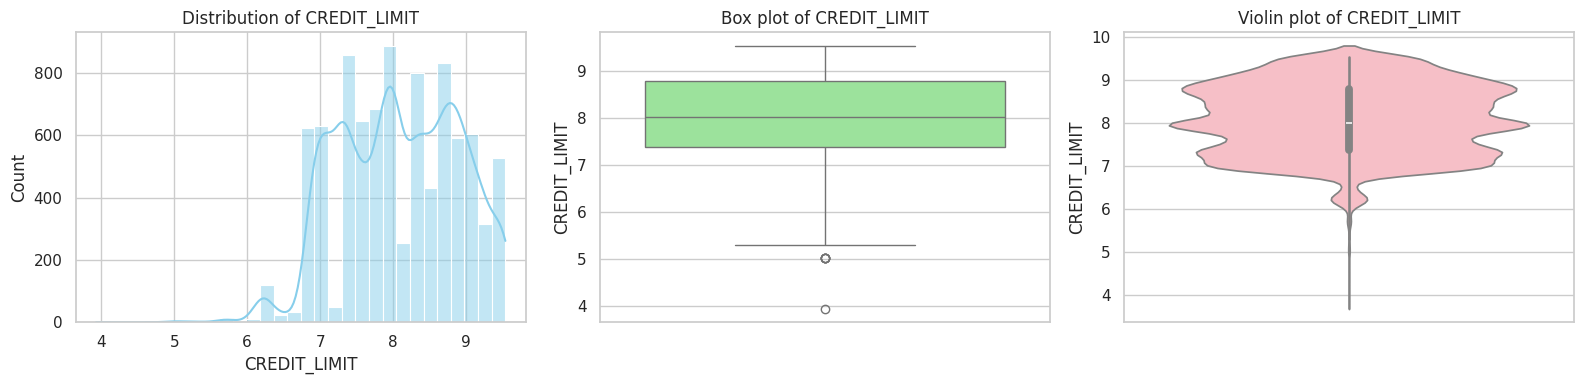

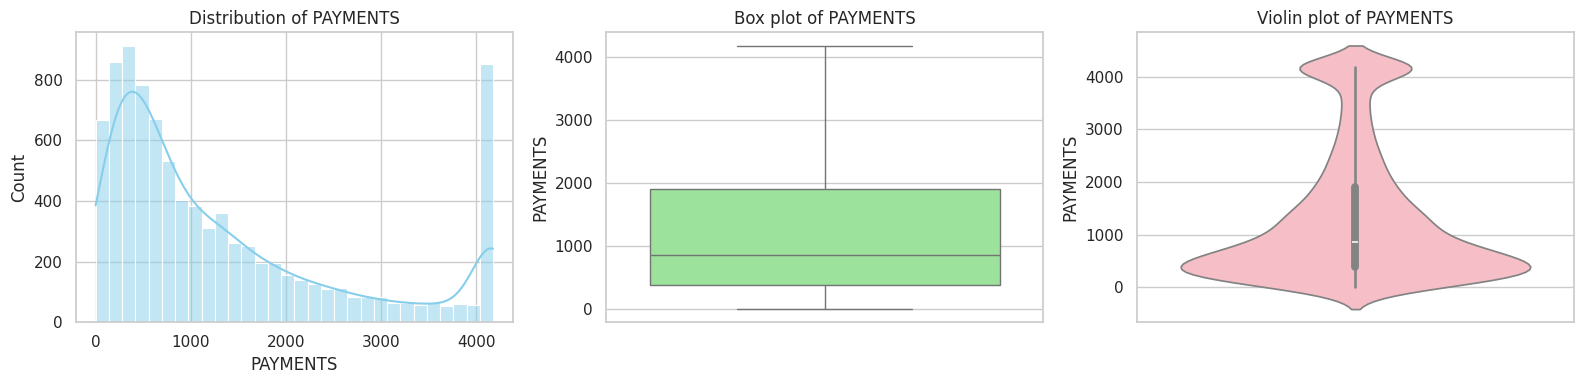

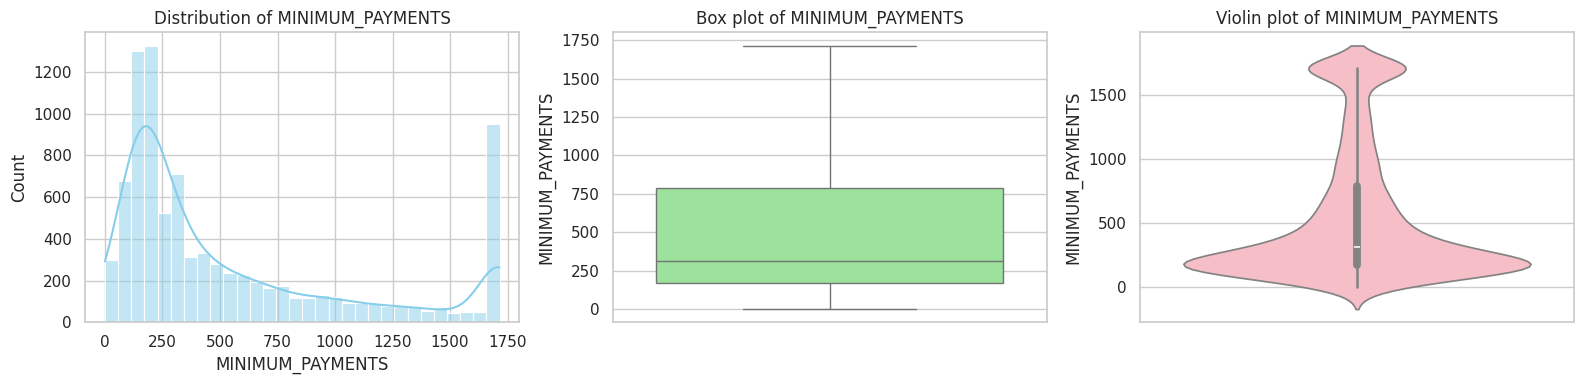

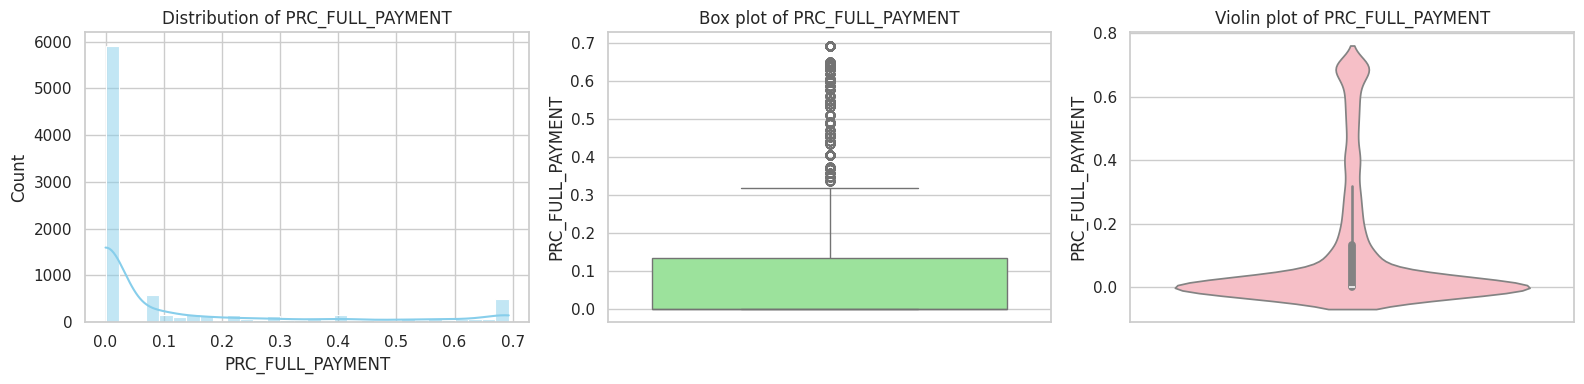

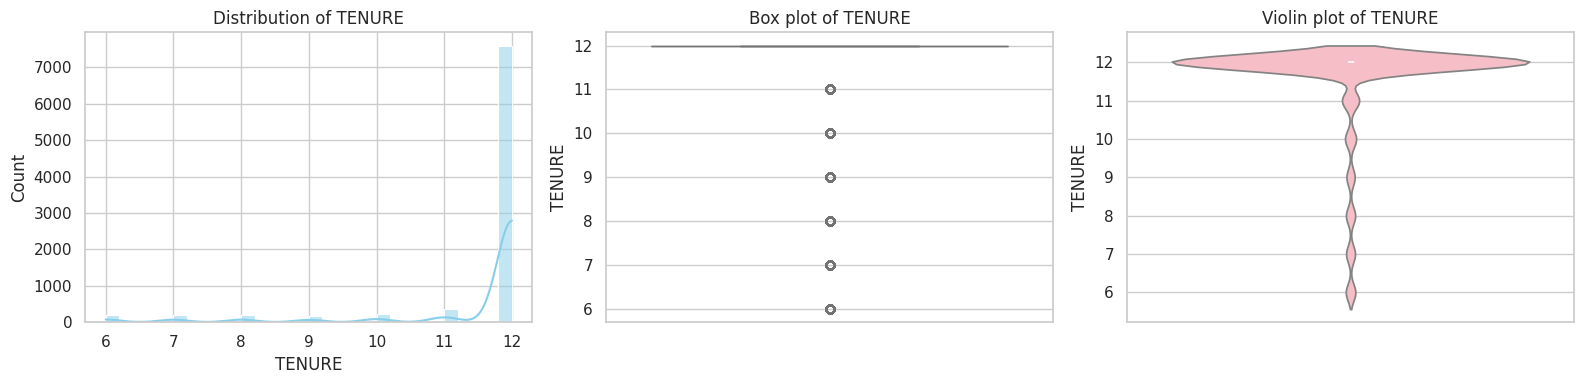

In [940]:
num_cols = df_scaled.select_dtypes(include='number').columns

for col in num_cols:
    plt.figure(figsize=(16,4))

    # Histogram
    plt.subplot(1,3,1)
    sns.histplot(df[col], kde=True, bins=30, color='skyblue')
    plt.title(f'Distribution of {col}')

    # Box Plot
    plt.subplot(1,3,2)
    sns.boxplot(y=df[col], color='lightgreen')
    plt.title(f'Box plot of {col}')

    # Violin Plot
    plt.subplot(1,3,3)
    sns.violinplot(y=df[col], color='lightpink')
    plt.title(f'Violin plot of {col}')

    plt.tight_layout()
    plt.show()

#**b. Bivariate Analysis**

**Correlation Heatmap**

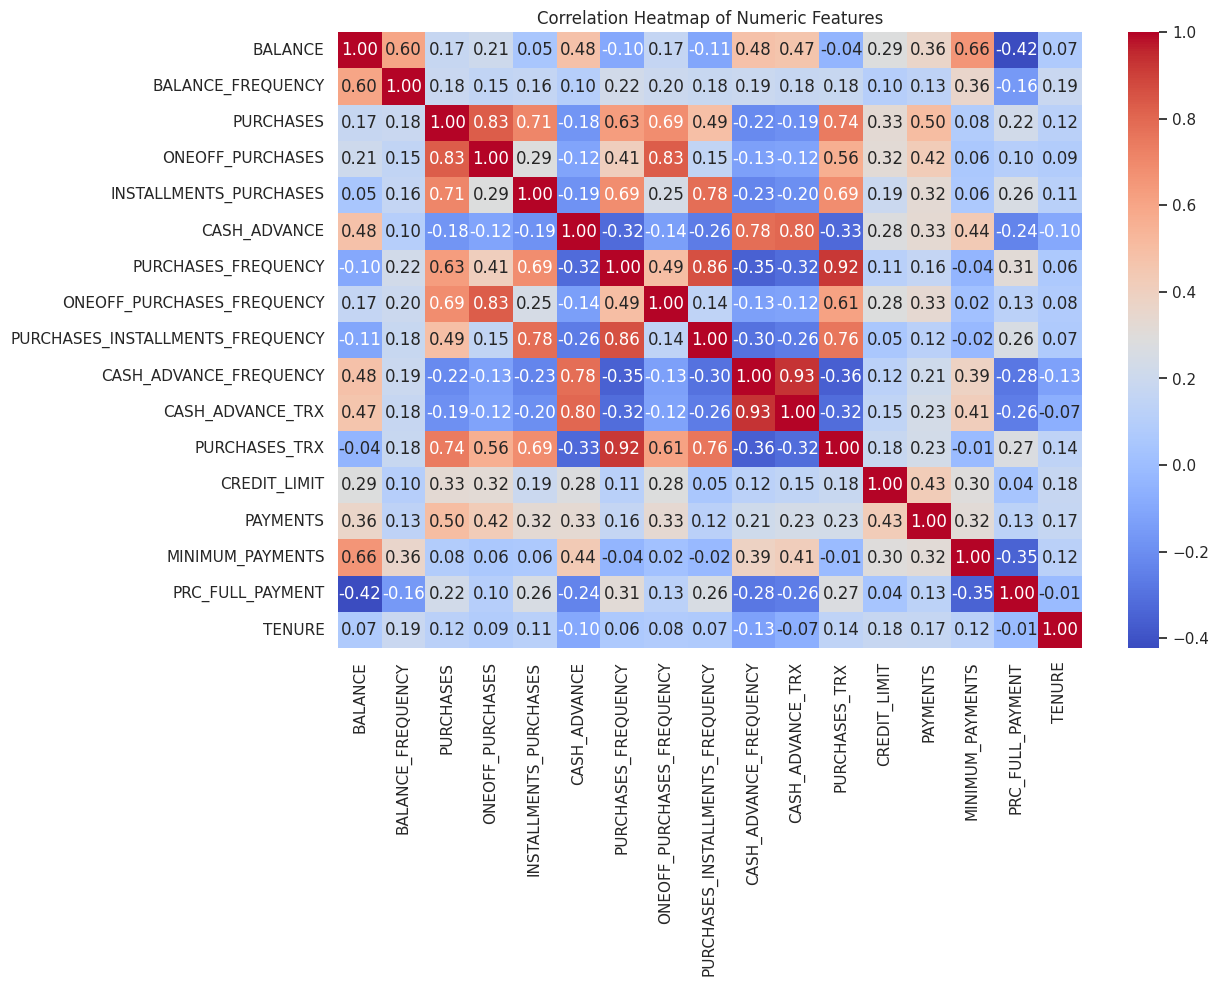

In [941]:
plt.figure(figsize=(12,8))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

**Scatterplots (Selected Relationships)**

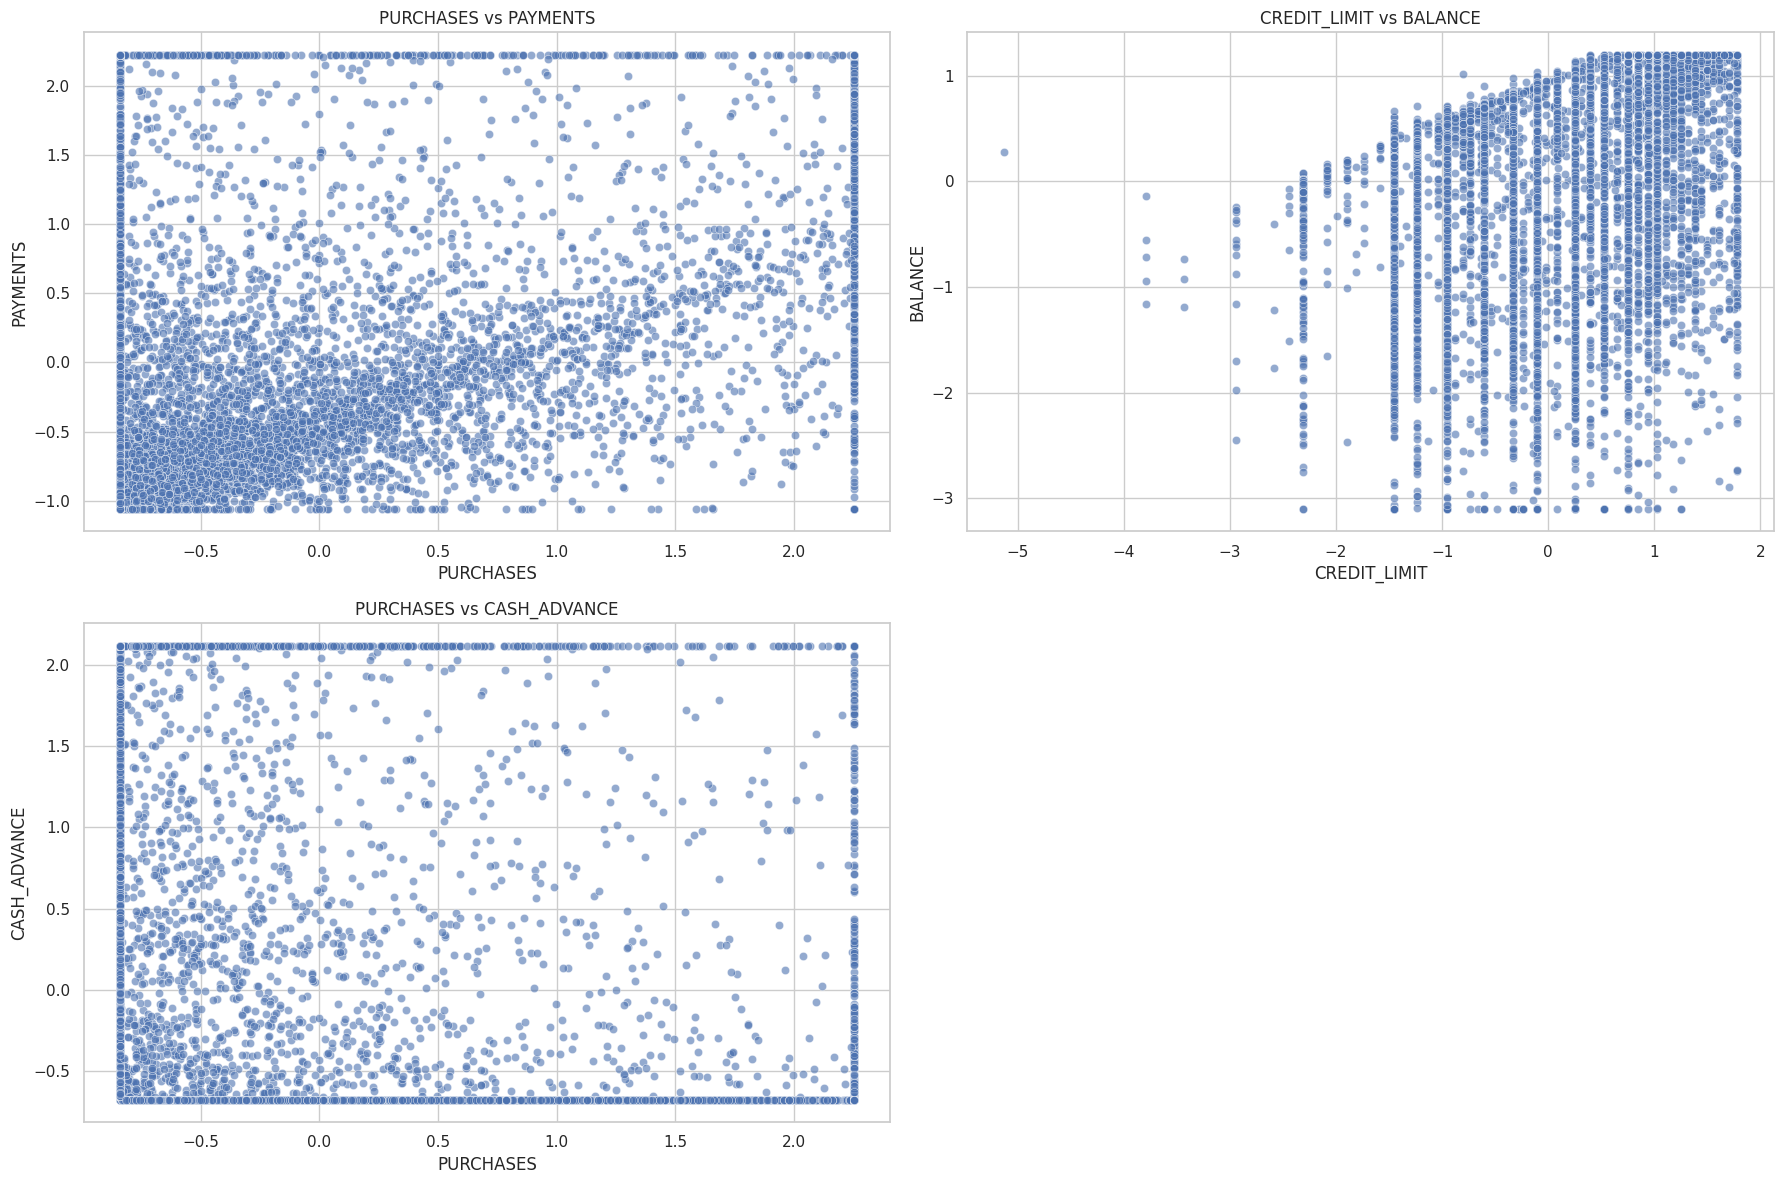

In [942]:
pairs = [
    ("PURCHASES", "PAYMENTS"),
    ("CREDIT_LIMIT", "BALANCE"),
    ("PURCHASES", "CASH_ADVANCE"),
]

plt.figure(figsize=(18, 12))

for i, (x, y) in enumerate(pairs, 1):
    plt.subplot(2, 2, i)
    sns.scatterplot(data=df_scaled, x=x, y=y, alpha=0.6)
    plt.title(f"{x} vs {y}")

plt.tight_layout()
plt.show()

#**c. Multivariate Analysis**

**Pair Plot on a Subset (to avoid clutter)**

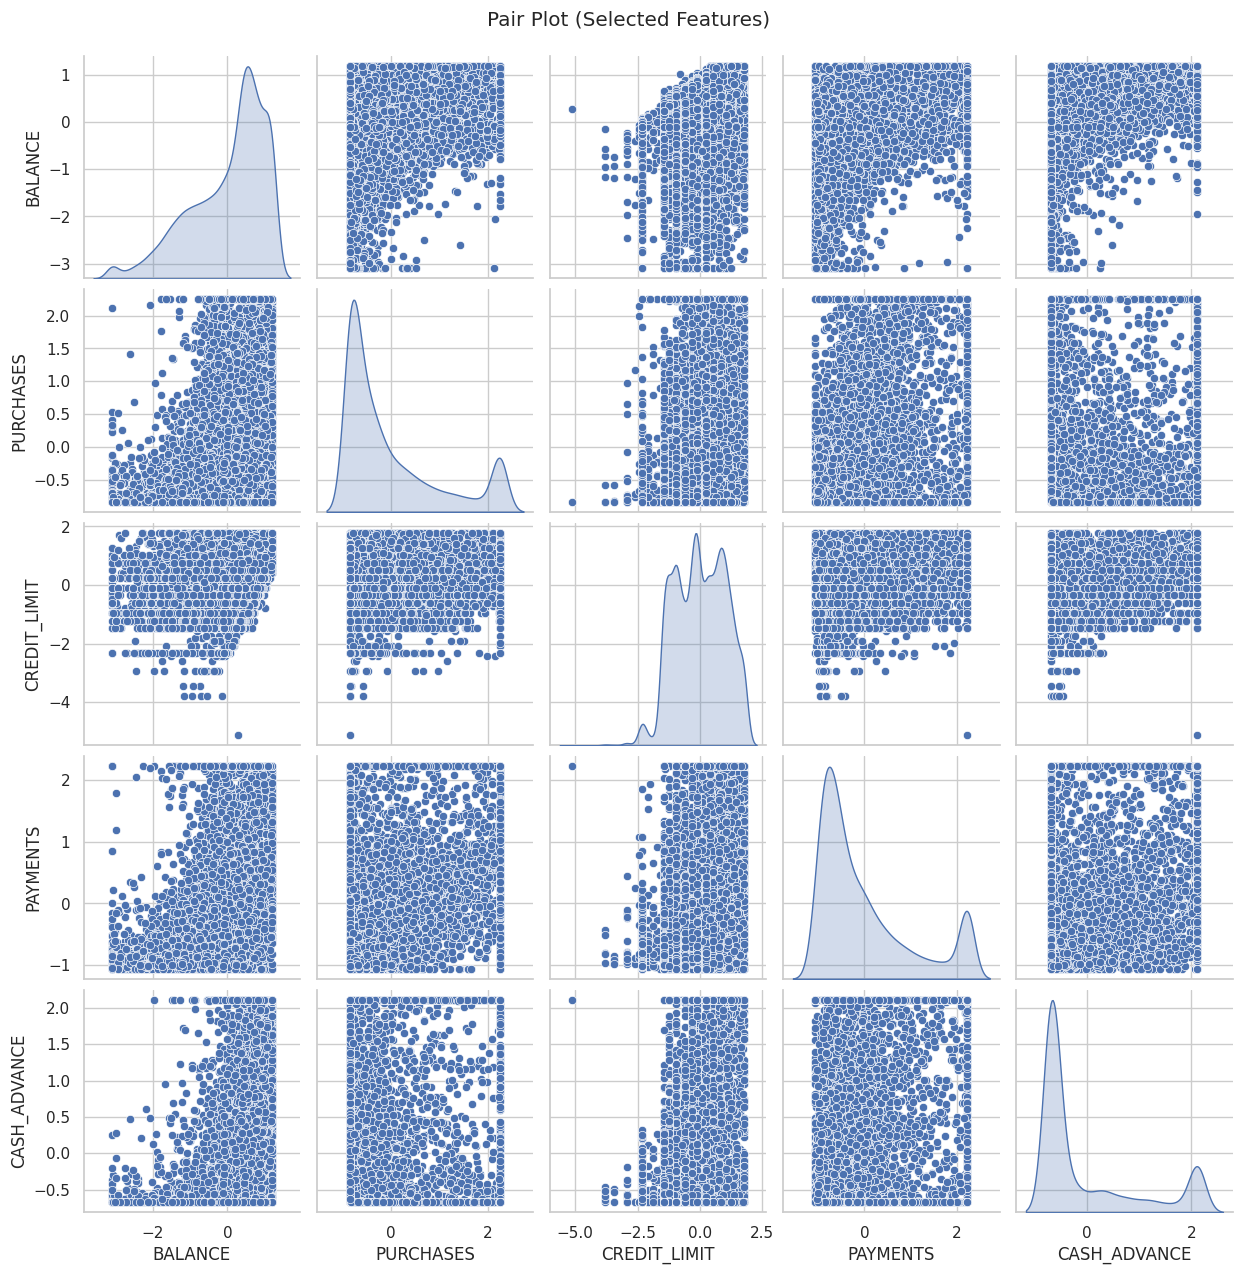

In [943]:
subset_cols = [
    "BALANCE", "PURCHASES", "CREDIT_LIMIT",
    "PAYMENTS", "CASH_ADVANCE",
]

sns.pairplot(df_scaled[subset_cols], diag_kind="kde")
plt.suptitle("Pair Plot (Selected Features)", y=1.02)
plt.show()


**Scatter Matrix (full multivariate structure)**

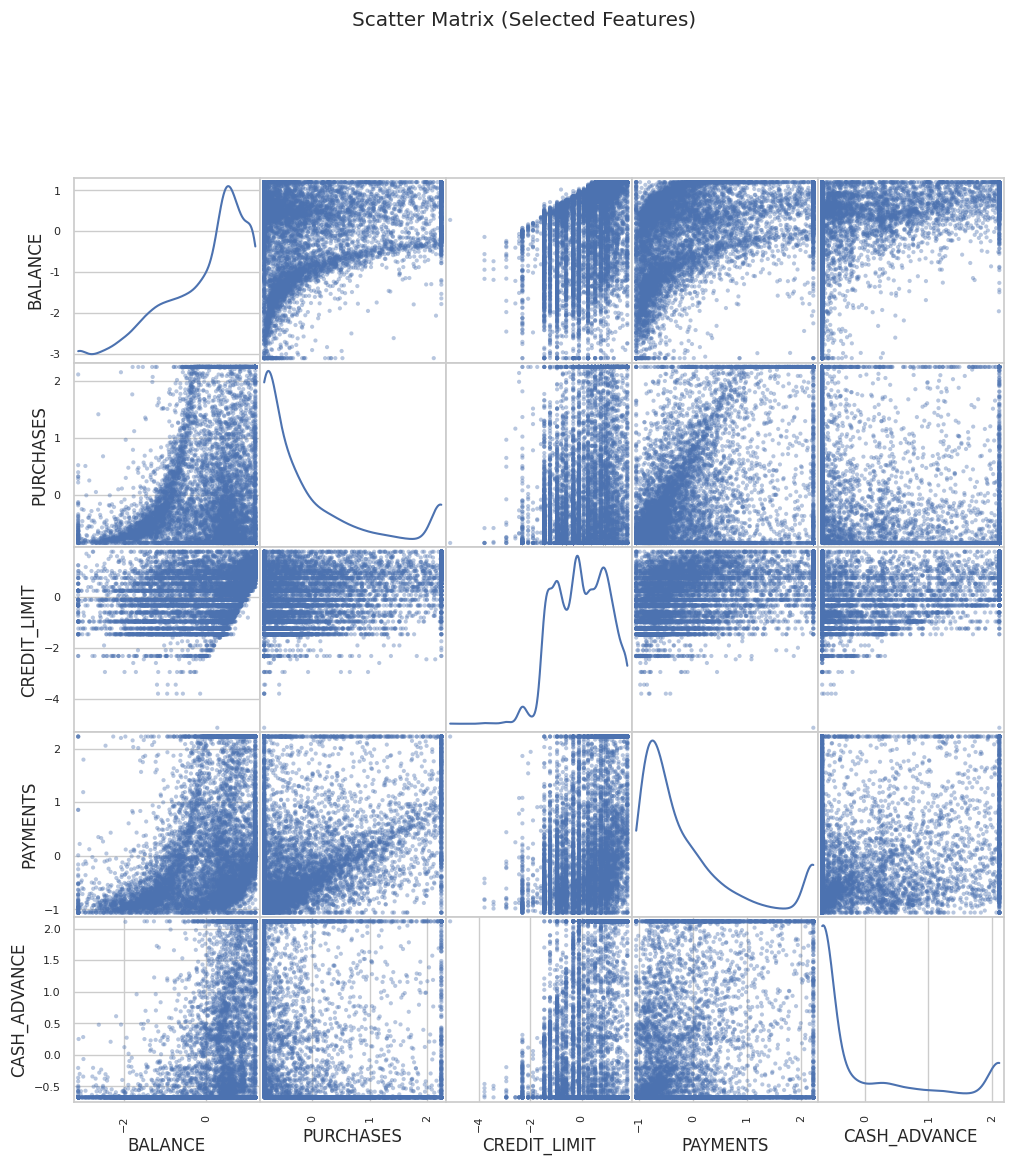

In [944]:
pd.plotting.scatter_matrix(df_scaled[subset_cols], figsize=(12, 12), diagonal="kde", alpha=0.4)
plt.suptitle("Scatter Matrix (Selected Features)", y=1.02)
plt.show()


#**4. Feature Engineering**

**Perform dimensionality analysis (PCA)**

=== PCA Explained Variance Table ===


,Component,Explained Variance (%),Cumulative Variance (%)
0,1,31.838,31.838
1,2,23.275,55.113
2,3,9.185,64.298
3,4,8.094,72.392
4,5,6.495,78.888
5,6,4.512,83.399
6,7,3.841,87.240
7,8,3.555,90.795
8,9,2.612,93.407
9,10,2.003,95.410



Number of PCA Components needed for 90% variance: 8


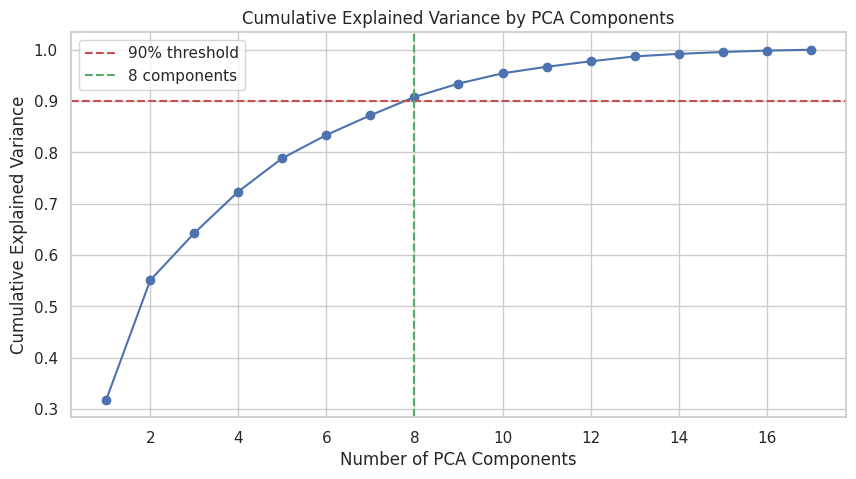

=== PCA Loadings (Feature Contributions) ===


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17
BALANCE,-0.042505,0.415411,0.089050,-0.288583,-0.088485,-0.064661,0.247464,-0.131410,-0.099203,-0.069598,0.351963,-0.448322,0.547252,-0.025631,0.047541,0.042992,-0.009641
BALANCE_FREQUENCY,0.068445,0.252815,0.285507,-0.408299,-0.115246,0.440027,0.453255,0.111187,-0.227979,0.110146,-0.134480,0.280680,-0.295386,0.078815,0.000457,-0.061947,0.013943
PURCHASES,0.365040,0.166638,-0.161499,0.030286,-0.063027,-0.074479,-0.041830,-0.226712,-0.168942,-0.344486,0.020090,0.247569,-0.012807,0.179874,-0.051916,0.504307,0.500865
ONEOFF_PURCHASES,0.281016,0.179378,-0.442367,-0.099209,-0.198585,0.034317,-0.100705,-0.065562,-0.008154,-0.174369,0.044960,0.469019,0.246116,-0.152637,0.017367,-0.304251,-0.446158
INSTALLMENTS_PURCHASES,0.325753,0.072234,0.308860,0.175558,0.096735,-0.168564,-0.020827,-0.237614,-0.315842,-0.406050,0.030578,-0.290672,-0.400404,-0.029877,0.018398,-0.185289,-0.349060
CASH_ADVANCE,-0.200413,0.348463,0.033978,0.317128,0.008036,0.013526,-0.097046,0.085284,0.004792,0.168088,0.734323,0.241617,-0.294632,0.001331,-0.079121,-0.015661,0.023330
PURCHASES_FREQUENCY,0.377611,0.008192,0.248952,0.081499,-0.136219,0.061444,-0.096196,0.216019,0.174414,0.276498,0.019091,-0.025169,0.085198,-0.004954,-0.018361,0.609911,-0.472223
ONEOFF_PURCHASES_FREQUENCY,0.277591,0.156491,-0.402907,-0.115945,-0.261037,0.171069,-0.105155,0.172686,0.167171,0.105265,0.009501,-0.458990,-0.380294,-0.370644,0.068296,-0.043795,0.214528
PURCHASES_INSTALLMENTS_FREQUENCY,0.318149,-0.017031,0.471914,0.155417,0.001899,-0.060815,-0.101779,0.063506,-0.036500,0.131893,-0.008350,0.200940,0.269559,-0.551673,0.083793,-0.240941,0.363712
CASH_ADVANCE_FREQUENCY,-0.224976,0.339272,0.074646,0.264048,-0.160146,0.239765,-0.193115,0.058226,-0.063519,-0.149710,-0.334769,-0.093174,0.118139,-0.102601,-0.680665,0.002558,-0.013251



=== Top 10 Features for PC1 ===


,PC1
PURCHASES_TRX,0.395258
PURCHASES_FREQUENCY,0.377611
PURCHASES,0.365040
INSTALLMENTS_PURCHASES,0.325753
PURCHASES_INSTALLMENTS_FREQUENCY,0.318149
ONEOFF_PURCHASES,0.281016
ONEOFF_PURCHASES_FREQUENCY,0.277591
CASH_ADVANCE_FREQUENCY,0.224976
CASH_ADVANCE_TRX,0.210593
CASH_ADVANCE,0.200413



=== Top 10 Features for PC2 ===


,PC2
BALANCE,0.415411
MINIMUM_PAYMENTS,0.356895
CASH_ADVANCE,0.348463
CASH_ADVANCE_TRX,0.347783
CASH_ADVANCE_FREQUENCY,0.339272
PAYMENTS,0.307460
CREDIT_LIMIT,0.254538
BALANCE_FREQUENCY,0.252815
ONEOFF_PURCHASES,0.179378
PURCHASES,0.166638



=== Top 10 Features for PC3 ===


,PC3
PURCHASES_INSTALLMENTS_FREQUENCY,0.471914
ONEOFF_PURCHASES,0.442367
ONEOFF_PURCHASES_FREQUENCY,0.402907
INSTALLMENTS_PURCHASES,0.308860
BALANCE_FREQUENCY,0.285507
PURCHASES_FREQUENCY,0.248952
CREDIT_LIMIT,0.208047
MINIMUM_PAYMENTS,0.186104
PAYMENTS,0.182279
PURCHASES,0.161499


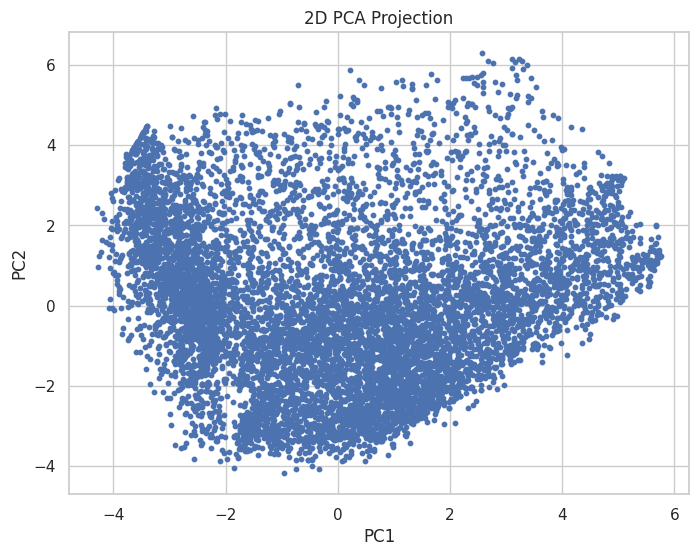

=== Interpretation Guide ===

1. The explained variance table shows how much information each PCA component captures.
   - A common target is 80–90% cumulative variance.

2. PCA loadings reveal which features influence each component.
   - Higher absolute values mean the feature is more important.

3. PCA 2D projection provides intuition about natural separation
   before clustering.

You are now ready for feature selection and clustering.



In [945]:
# 1. Fit PCA on all features
# -------------------------------
pca = PCA()
pca.fit(df_scaled)

explained_var = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

# -------------------------------
# 2. Display PCA explained variance table
# -------------------------------
pca_table = pd.DataFrame({
    "Component": range(1, len(explained_var) + 1),
    "Explained Variance (%)": np.round(explained_var * 100, 3),
    "Cumulative Variance (%)": np.round(cum_var * 100, 3)
})

print("=== PCA Explained Variance Table ===")
display(pca_table)

# Automatically identify number of components needed for 90% variance
k_90 = np.argmax(cum_var >= 0.90) + 1
print(f"\nNumber of PCA Components needed for 90% variance: {k_90}")

# -------------------------------
# 3. Cumulative variance plot
# -------------------------------
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained_var) + 1), cum_var, marker='o')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% threshold')
plt.axvline(x=k_90, color='g', linestyle='--', label=f'{k_90} components')
plt.title("Cumulative Explained Variance by PCA Components")
plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

# -------------------------------
# 4. PCA Loadings (Feature Contributions)
# -------------------------------
loadings = pd.DataFrame(
    pca.components_.T,
    index=df_scaled.columns,
    columns=[f"PC{i+1}" for i in range(len(df_scaled.columns))]
)

print("=== PCA Loadings (Feature Contributions) ===")
display(loadings)

# -------------------------------
# 5. Top features for first 3 PCs
# -------------------------------
for pc in ["PC1", "PC2", "PC3"]:
    print(f"\n=== Top 10 Features for {pc} ===")
    display(loadings[pc].abs().sort_values(ascending=False).head(10))

# -------------------------------
# 6. 2D PCA Visualization
# -------------------------------
pca_2d = PCA(n_components=2)
df_pca_2d = pca_2d.fit_transform(df_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(df_pca_2d[:, 0], df_pca_2d[:, 1], s=10)
plt.title("2D PCA Projection")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()

# -------------------------------
# 7. Interpretation summary
# -------------------------------
print("=== Interpretation Guide ===")
print("""
1. The explained variance table shows how much information each PCA component captures.
   - A common target is 80–90% cumulative variance.

2. PCA loadings reveal which features influence each component.
   - Higher absolute values mean the feature is more important.

3. PCA 2D projection provides intuition about natural separation
   before clustering.

You are now ready for feature selection and clustering.
""")



**Select most important features for clustering**

In [946]:
# 1. Recompute PCA using only components needed for 90% variance
pca_k = PCA(n_components=k_90)
pca_k.fit(df_scaled)

# 2. Loadings for first k components
loadings_k = pd.DataFrame(
    np.abs(pca_k.components_).T,
    index=df.columns,
    columns=[f"PC{i+1}" for i in range(k_90)]
)

# 3. Compute global importance score of each feature
feature_importance = loadings_k.sum(axis=1)

# 4. Automatic threshold: mean importance
threshold = feature_importance.mean()

# 5. Select features above threshold
selected_features = feature_importance[feature_importance >= threshold].index.tolist()

print("\n=== AUTOMATIC FEATURE SELECTION ===")
print("Threshold:", threshold)
print("Selected features:", selected_features)

# 6. Final dataset for clustering
df_selected = df_scaled[selected_features]

print("\nShape before:", df.shape)
print("Shape after:", df_selected.shape)


=== AUTOMATIC FEATURE SELECTION ===
Threshold: 1.558495809905288
Selected features: ['BALANCE_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'CASH_ADVANCE_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

Shape before: (8950, 17)
Shape after: (8950, 7)


#**5. Modeling & Analysis**

#**a.K-Means Clustering**

**Elbow Method**

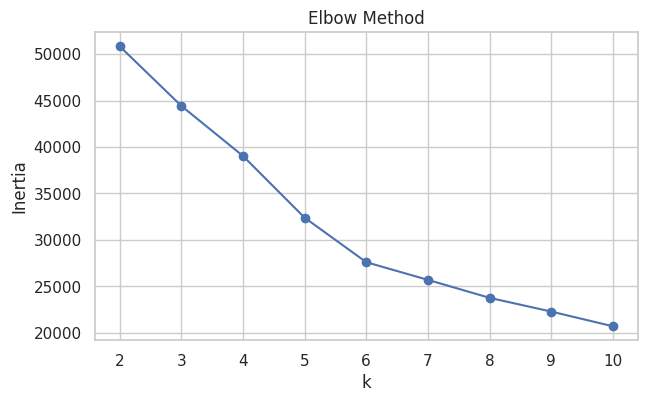

In [947]:
inertia = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(df_selected)
    inertia.append(km.inertia_)

plt.figure(figsize=(7,4))
plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

**Silhouette Analysis**

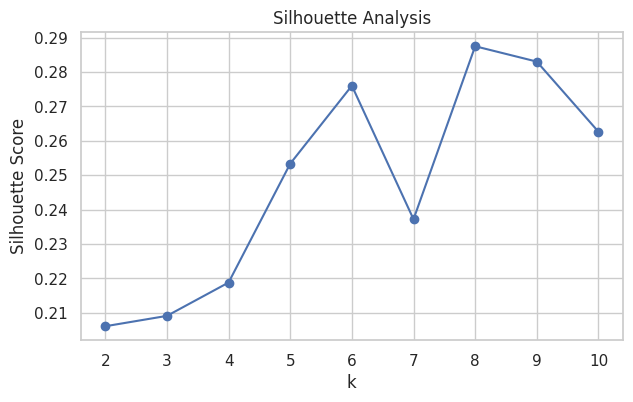

Best K from Silhouette = 8


In [948]:
silhouette_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(df_selected)
    sil = silhouette_score(df_selected, labels)
    silhouette_scores.append(sil)

plt.figure(figsize=(7,4))
plt.plot(K_range, silhouette_scores, marker='o')
plt.title("Silhouette Analysis")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.show()

best_k_silhouette = K_range[np.argmax(silhouette_scores)]
print("Best K from Silhouette =", best_k_silhouette)

In [949]:
optimal_k = best_k_silhouette
print("Final chosen K =", optimal_k)

kmeans = KMeans(n_clusters=optimal_k, random_state=42)

df_selected = df_selected.copy()
df_selected.loc[:, 'cluster_kmeans'] = kmeans.fit_predict(df_selected)

Final chosen K = 8


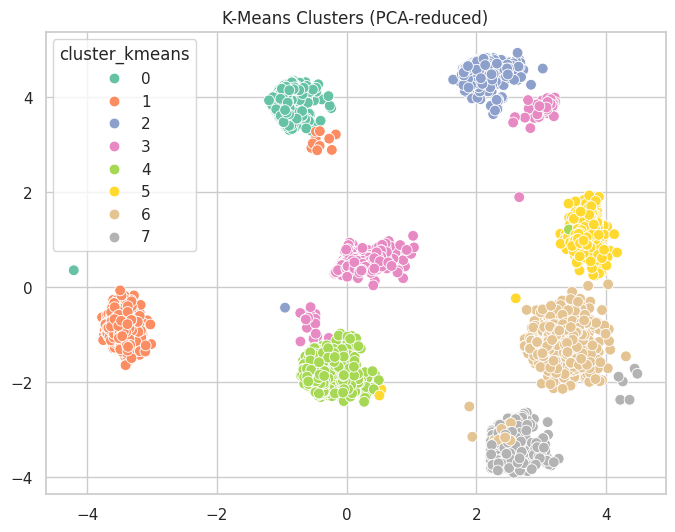

In [963]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(df_selected)

plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=df_selected['cluster_kmeans'], palette='Set2', s=60)
plt.title('K-Means Clusters (PCA-reduced)')
plt.show()

#**b. Hierarchical Clustering**

In [950]:
from sklearn.cluster import AgglomerativeClustering

hier = AgglomerativeClustering(n_clusters=8, linkage='ward')

df_selected.loc[:, 'cluster_hier'] = hier.fit_predict(df_selected)


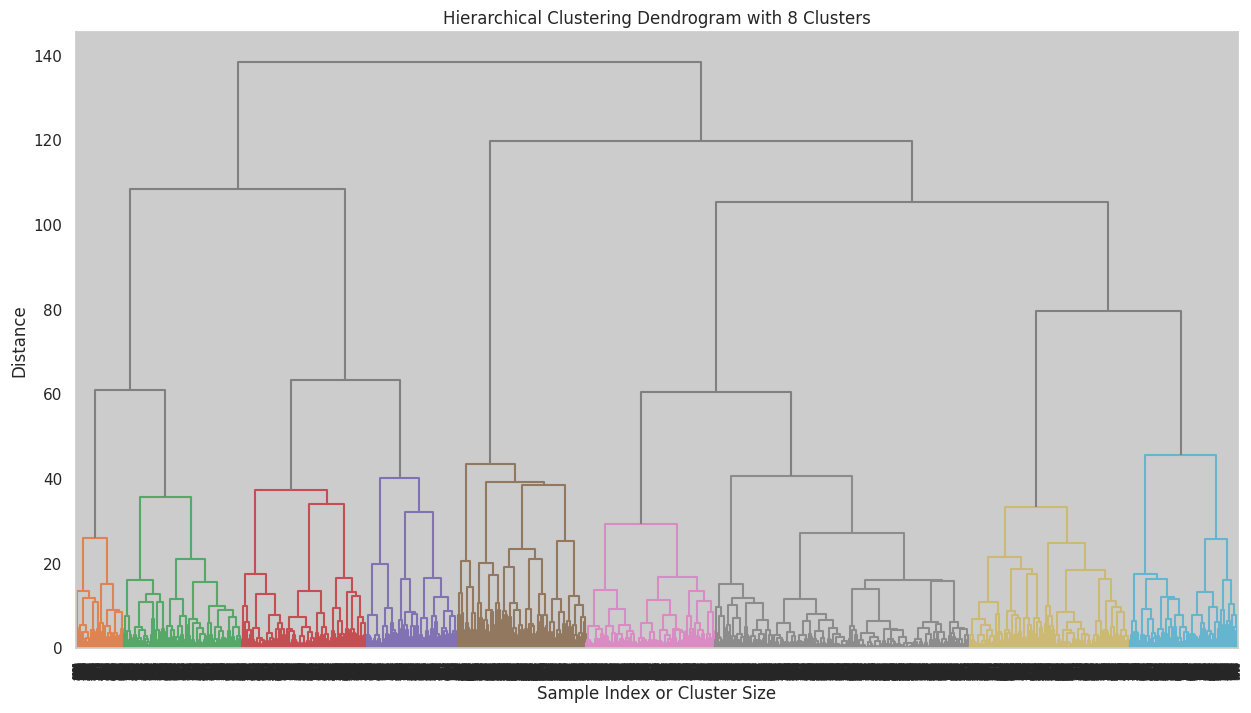

In [964]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Prepare data for linkage calculation (excluding cluster assignments)
df_for_dendrogram = df_selected.drop(columns=['cluster_kmeans', 'cluster_hier'])

# Calculate the linkage matrix
Z = linkage(df_for_dendrogram, method='ward')

# Determine the color threshold to highlight 8 clusters
# The height for cutting to k clusters is at Z[-(k), 2]
color_threshold = Z[-(optimal_k), 2]

plt.figure(figsize=(15, 8))
plt.title('Hierarchical Clustering Dendrogram with 8 Clusters')
plt.xlabel('Sample Index or Cluster Size')
plt.ylabel('Distance')

# Plot the dendrogram
dendrogram(
    Z,
    color_threshold=color_threshold, # Color branches below this threshold
    above_threshold_color='grey'    # Color branches above the threshold grey
    # Optionally, you can truncate the dendrogram for better readability with many samples
    # truncate_mode='lastp',  # show only the last p merged clusters
    # p=30,  # show only the last 30 merges
)
plt.show()

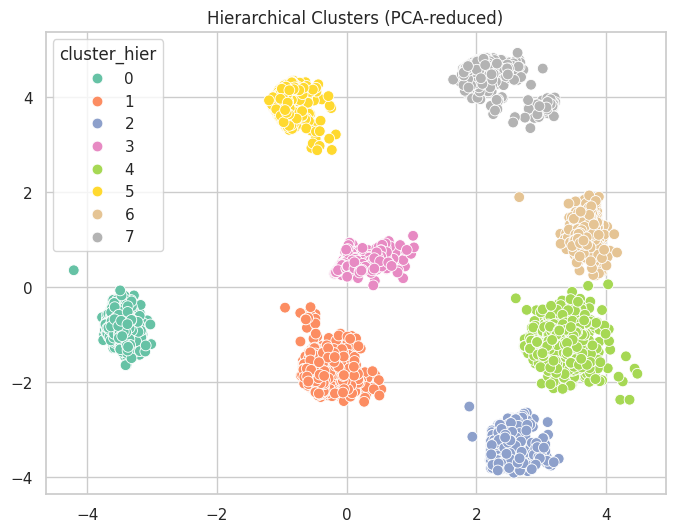

In [968]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(df_selected)

plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=df_selected['cluster_hier'], palette='Set2', s=60)
plt.title('Hierarchical Clusters (PCA-reduced)')
plt.show()

#**6. Results & Interpretation**

#**Analyze & Profile Each Customer Segment**

In [951]:
profile_kmeans = df_selected.groupby("cluster_kmeans")[selected_features].mean()
profile_hier   = df_selected.groupby("cluster_hier")[selected_features].mean()

print("=== K-MEANS CLUSTER PROFILE ===")
display(profile_kmeans)

print("\n=== HIERARCHICAL CLUSTER PROFILE ===")
display(profile_hier)

print("K-Means cluster sizes:\n", df_selected['cluster_kmeans'].value_counts())
print("\nHierarchical cluster sizes:\n", df_selected['cluster_hier'].value_counts())


=== K-MEANS CLUSTER PROFILE ===


,BALANCE_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,CASH_ADVANCE_TRX,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
cluster_kmeans,,,,,,,
0,0.548293,1.613180,-0.435263,0.561547,0.408730,-0.375233,0.305911
1,0.566905,-0.457312,-0.285385,-0.506714,-0.527883,-0.445207,0.292305
2,0.289923,1.798127,-0.573433,0.734080,1.095031,2.184135,0.279690
3,-0.555056,-0.537299,-0.660868,-0.088035,-0.344744,2.178772,0.179747
4,-0.165010,-0.338668,-0.061157,0.750268,1.653088,-0.184755,0.263964
5,-1.789852,-0.430351,-0.467940,-0.283991,-0.581333,-0.235129,0.251707
6,-0.579197,-0.255688,0.169436,-0.655422,-0.619177,-0.048773,-3.139841
7,0.476448,-0.192658,1.944845,0.558066,0.544617,-0.434532,0.202034



=== HIERARCHICAL CLUSTER PROFILE ===


,BALANCE_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,CASH_ADVANCE_TRX,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
cluster_hier,,,,,,,
0,0.566724,-0.463850,-0.284951,-0.500498,-0.527054,-0.445612,0.293145
1,-0.220233,-0.344539,-0.071112,0.725997,1.662185,-0.107408,0.261567
2,0.453347,-0.199091,1.945448,0.547524,0.524998,-0.435622,0.187274
3,-0.449528,-0.624996,-0.674008,-0.096066,-0.428373,2.165155,0.173308
4,-0.551067,-0.241892,0.143004,-0.651618,-0.598760,-0.041737,-3.157627
5,0.548863,1.610871,-0.435008,0.538375,0.399005,-0.374890,0.303872
6,-1.790254,-0.432977,-0.463725,-0.285244,-0.583591,-0.229791,0.252817
7,0.139145,1.716701,-0.587501,0.673530,0.991632,2.185446,0.279366


K-Means cluster sizes:
 cluster_kmeans
1    2754
7    1300
0    1187
5    1152
3     731
6     688
4     649
2     489
Name: count, dtype: int64

Hierarchical cluster sizes:
 cluster_hier
0    2744
2    1310
5    1197
6    1150
4     679
1     671
3     666
7     533
Name: count, dtype: int64


#**Interpret Cluster Characteristics**

In [952]:
def interpret_clusters(profile, method_name):
    print(f"\n\n=== INTERPRETATION FOR {method_name} ===")
    for c in profile.index:
        print(f"\nCluster {c}:")
        desc = profile.loc[c]
        high = desc[desc > desc.mean()].index.tolist()
        low  = desc[desc < desc.mean()].index.tolist()
        print(f" • High values: {', '.join(high) if high else 'None'}")
        print(f" • Low values: {', '.join(low) if low else 'None'}")

interpret_clusters(profile_kmeans, "K-MEANS")
interpret_clusters(profile_hier, "HIERARCHICAL")




=== INTERPRETATION FOR K-MEANS ===

Cluster 0:
 • High values: BALANCE_FREQUENCY, ONEOFF_PURCHASES_FREQUENCY, CREDIT_LIMIT, PAYMENTS
 • Low values: CASH_ADVANCE_TRX, PRC_FULL_PAYMENT, TENURE

Cluster 1:
 • High values: BALANCE_FREQUENCY, TENURE
 • Low values: ONEOFF_PURCHASES_FREQUENCY, CASH_ADVANCE_TRX, CREDIT_LIMIT, PAYMENTS, PRC_FULL_PAYMENT

Cluster 2:
 • High values: ONEOFF_PURCHASES_FREQUENCY, PAYMENTS, PRC_FULL_PAYMENT
 • Low values: BALANCE_FREQUENCY, CASH_ADVANCE_TRX, CREDIT_LIMIT, TENURE

Cluster 3:
 • High values: PRC_FULL_PAYMENT, TENURE
 • Low values: BALANCE_FREQUENCY, ONEOFF_PURCHASES_FREQUENCY, CASH_ADVANCE_TRX, CREDIT_LIMIT, PAYMENTS

Cluster 4:
 • High values: CREDIT_LIMIT, PAYMENTS
 • Low values: BALANCE_FREQUENCY, ONEOFF_PURCHASES_FREQUENCY, CASH_ADVANCE_TRX, PRC_FULL_PAYMENT, TENURE

Cluster 5:
 • High values: ONEOFF_PURCHASES_FREQUENCY, CASH_ADVANCE_TRX, CREDIT_LIMIT, PRC_FULL_PAYMENT, TENURE
 • Low values: BALANCE_FREQUENCY, PAYMENTS

Cluster 6:
 • High values:

#**Create cluster visualization:**

**a.Cluster Visualization: 2D PCA**

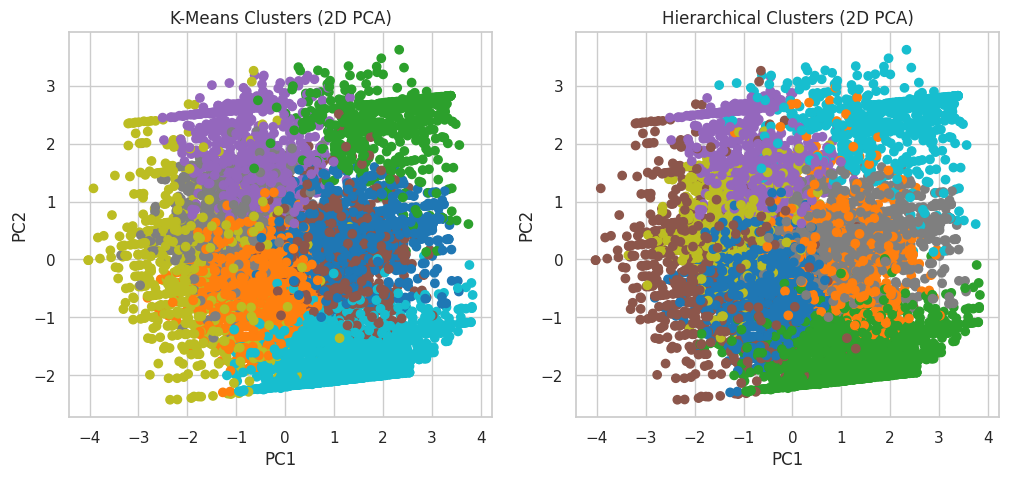

In [965]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
pca_2d = pca.fit_transform(df_selected[selected_features])

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(pca_2d[:,0], pca_2d[:,1], c=df_selected['cluster_kmeans'], cmap='tab10')
plt.title("K-Means Clusters (2D PCA)")
plt.xlabel("PC1"); plt.ylabel("PC2")

plt.subplot(1,2,2)
plt.scatter(pca_2d[:,0], pca_2d[:,1], c=df_selected['cluster_hier'], cmap='tab10')
plt.title("Hierarchical Clusters (2D PCA)")
plt.xlabel("PC1"); plt.ylabel("PC2")

plt.show()

**b.Cluster Visualization: 3D PCA**

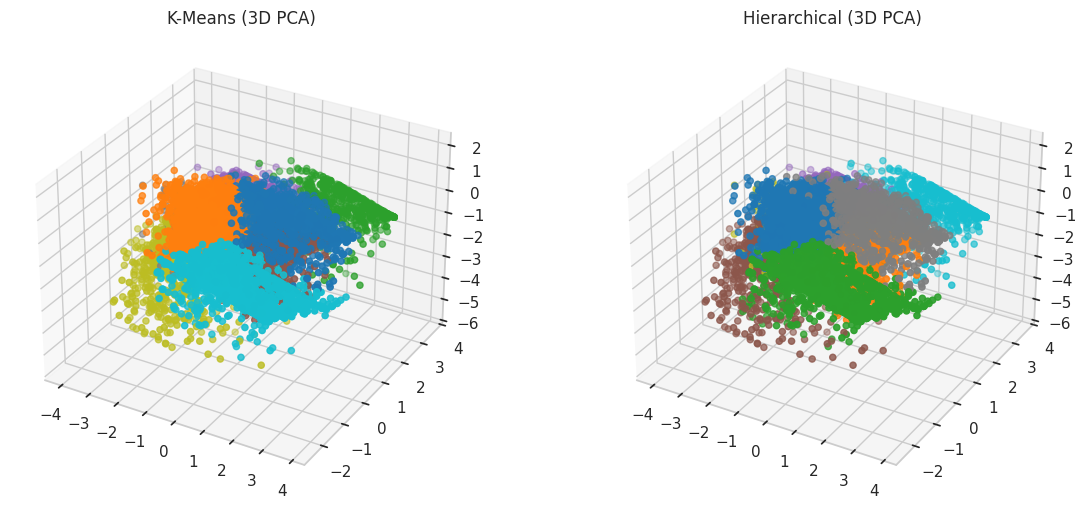

In [966]:
from mpl_toolkits.mplot3d import Axes3D

pca3 = PCA(n_components=3)
pca_3d = pca3.fit_transform(df_selected[selected_features])

fig = plt.figure(figsize=(14,6))

ax = fig.add_subplot(121, projection='3d')
ax.scatter(pca_3d[:,0], pca_3d[:,1], pca_3d[:,2],
           c=df_selected['cluster_kmeans'], cmap='tab10')
ax.set_title("K-Means (3D PCA)")

ax = fig.add_subplot(122, projection='3d')
ax.scatter(pca_3d[:,0], pca_3d[:,1], pca_3d[:,2],
           c=df_selected['cluster_hier'], cmap='tab10')
ax.set_title("Hierarchical (3D PCA)")

plt.show()

#**Cluster Profiling Charts (Bar plots for both methods)**

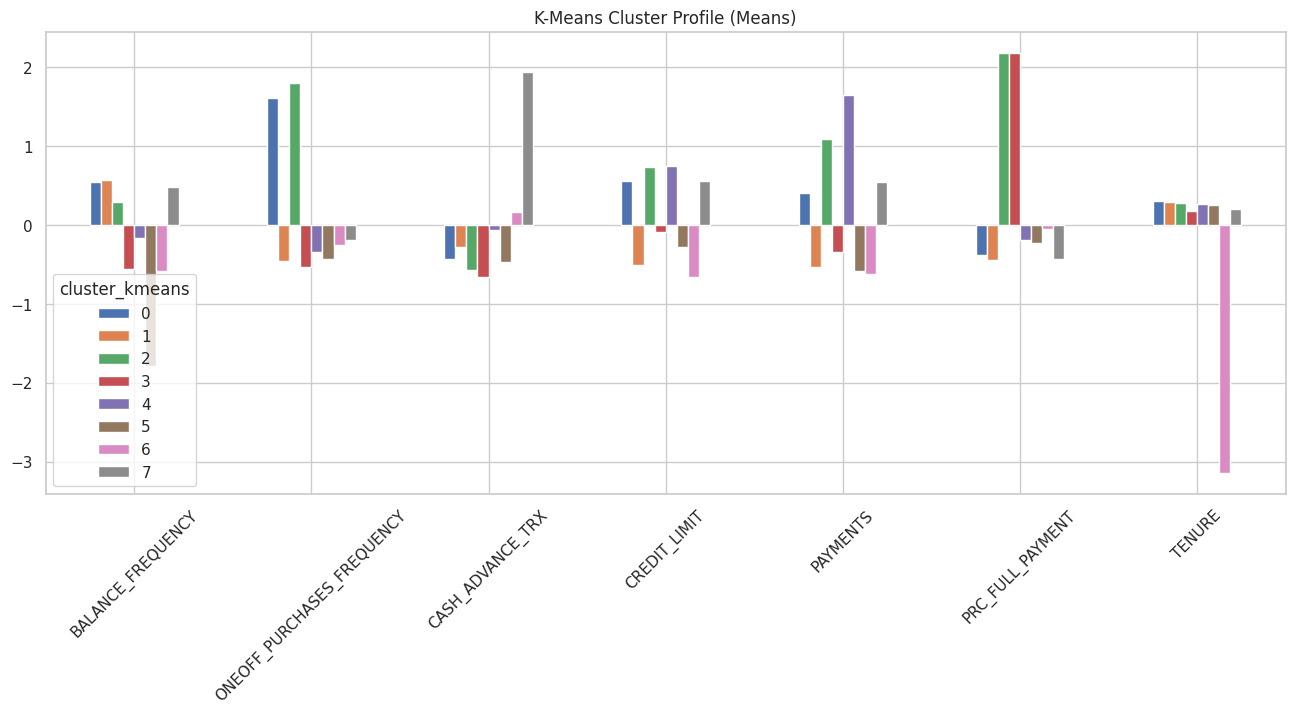

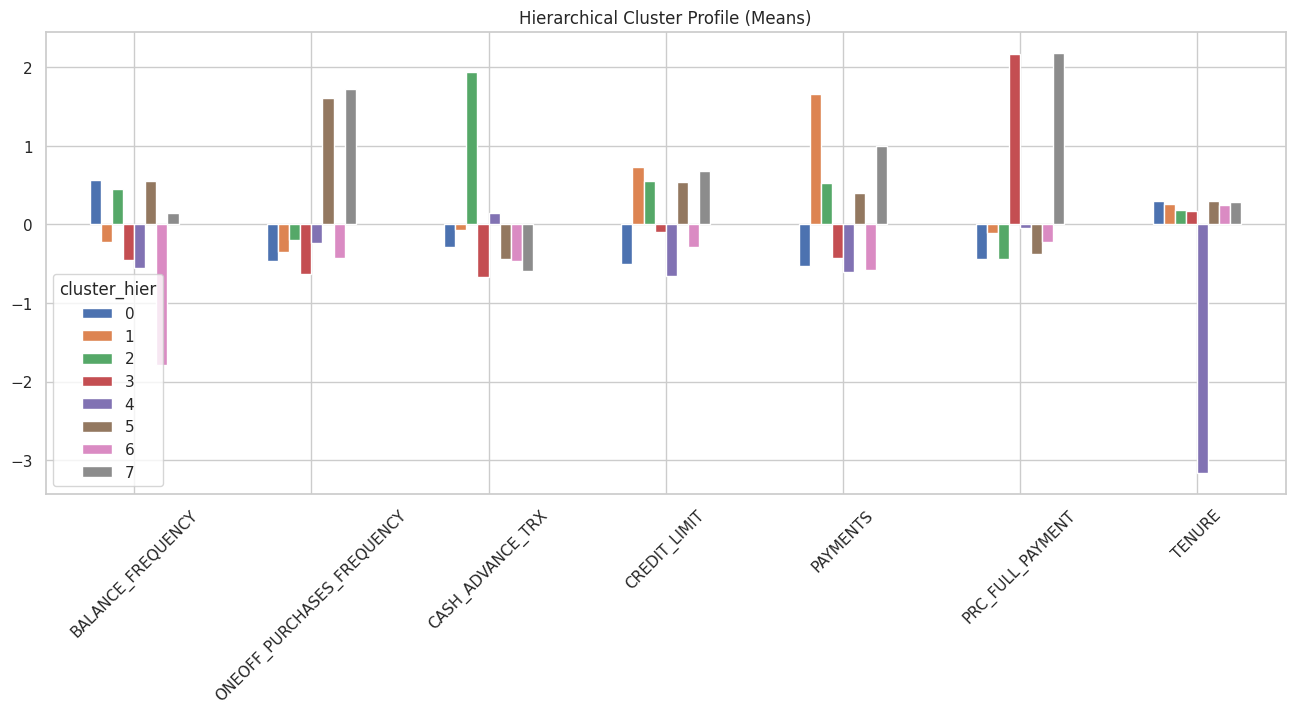

In [955]:
profile_kmeans.T.plot(kind='bar', figsize=(16,6), title='K-Means Cluster Profile (Means)')
plt.xticks(rotation=45)
plt.show()

profile_hier.T.plot(kind='bar', figsize=(16,6), title='Hierarchical Cluster Profile (Means)')
plt.xticks(rotation=45)
plt.show()


#**Comparative analysis between segments**

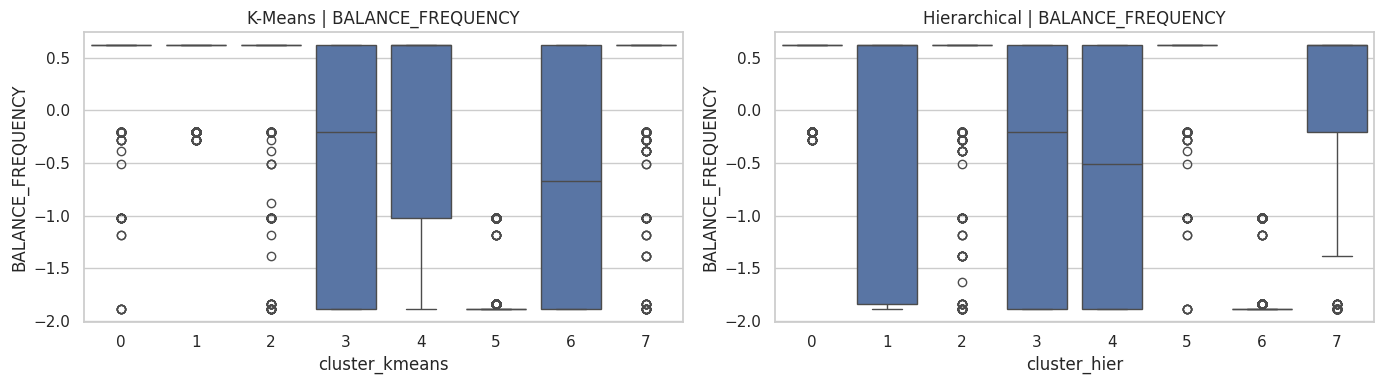

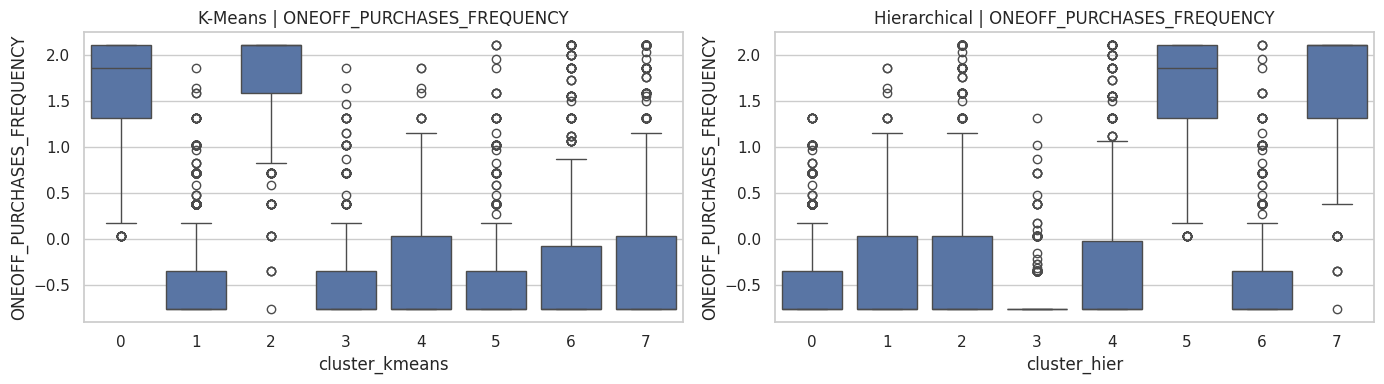

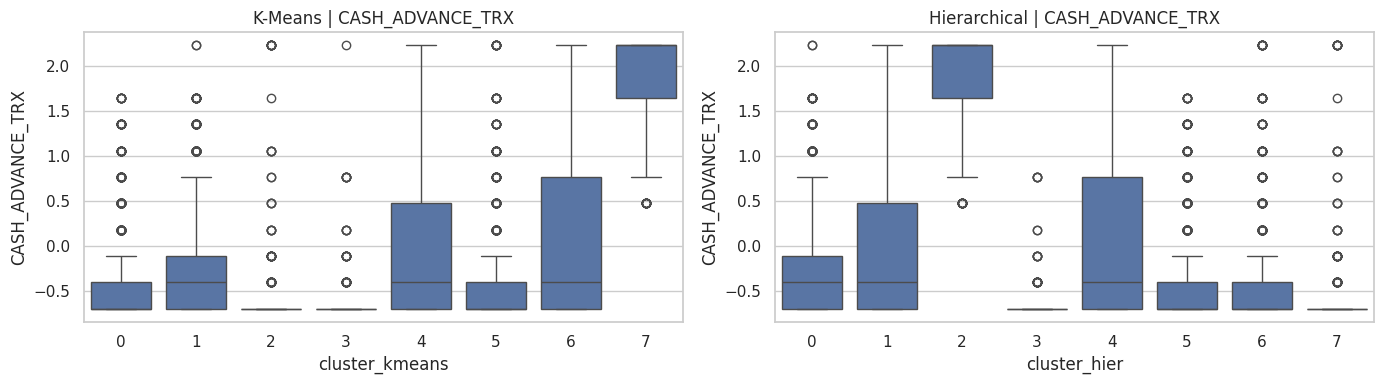

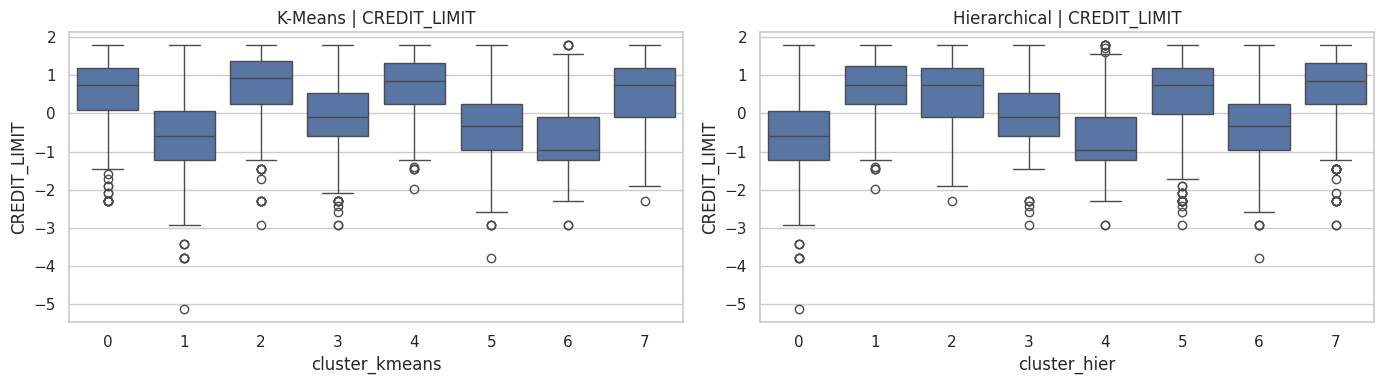

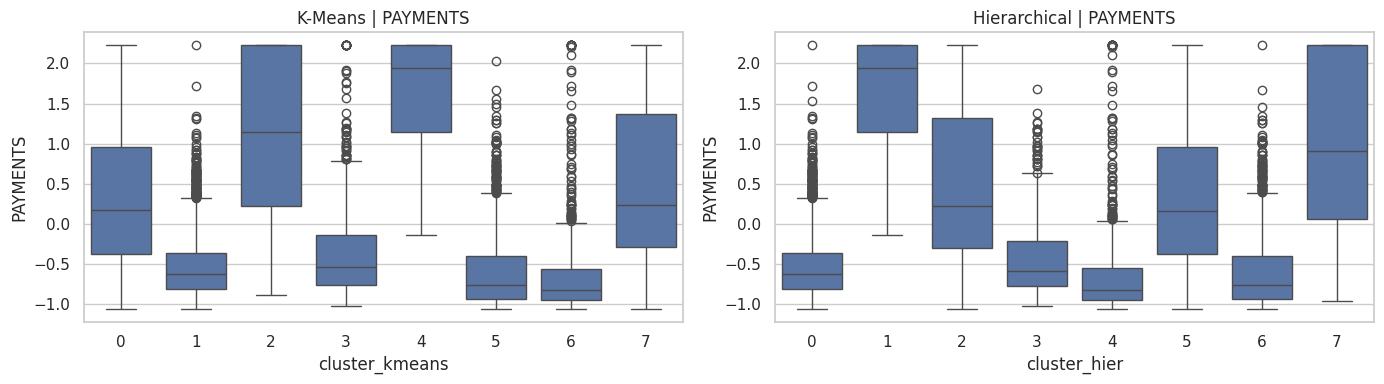

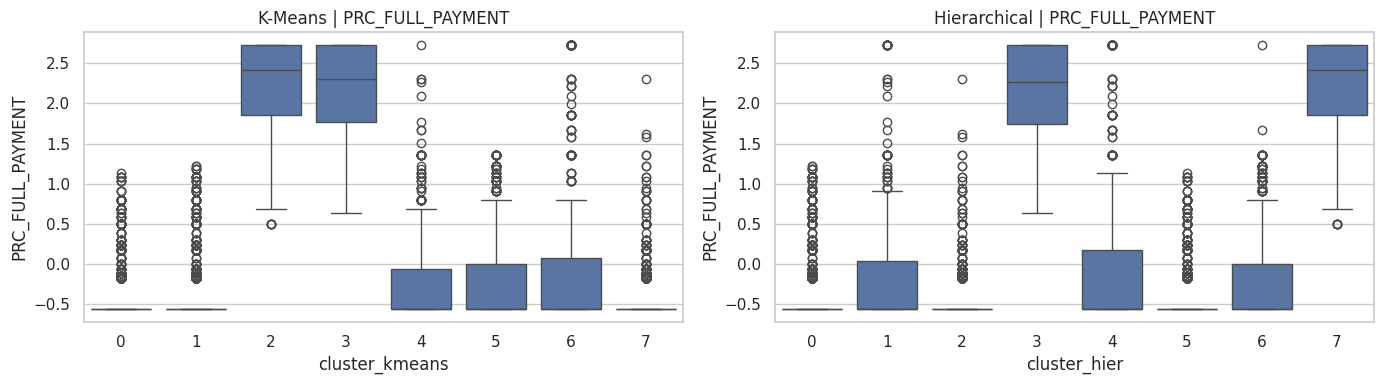

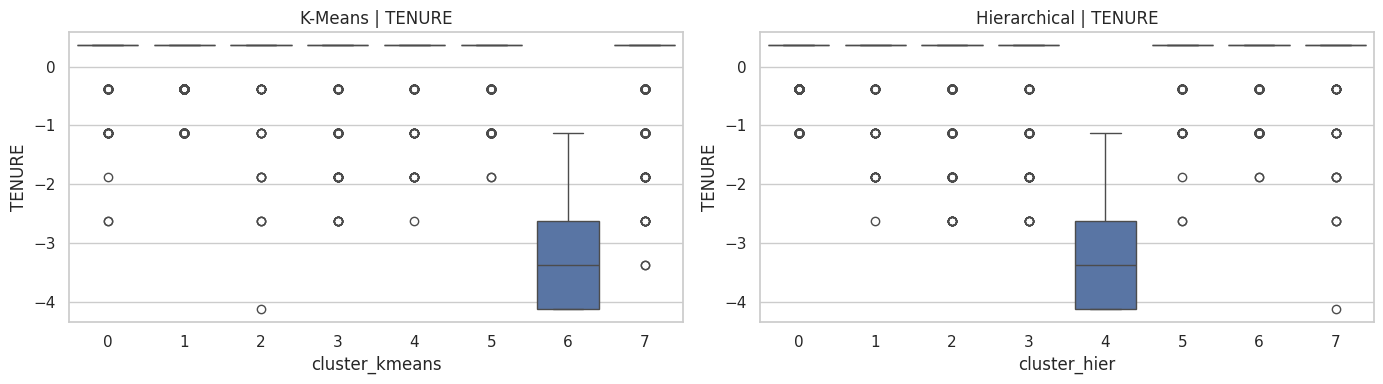

In [956]:
import seaborn as sns

for col in selected_features:
    plt.figure(figsize=(14,4))

    plt.subplot(1,2,1)
    sns.boxplot(x=df_selected['cluster_kmeans'], y=df_selected[col])
    plt.title(f"K-Means | {col}")

    plt.subplot(1,2,2)
    sns.boxplot(x=df_selected['cluster_hier'], y=df_selected[col])
    plt.title(f"Hierarchical | {col}")

    plt.tight_layout()
    plt.show()


#**Compare Segmentation Methods (Cross-Tab + Heatmap)**

**a.Cluster Overlap Table**

In [957]:
comparison = pd.crosstab(df_selected['cluster_kmeans'],
                         df_selected['cluster_hier'])

print("Comparison Between K-Means and Hierarchical:")
display(comparison)


Comparison Between K-Means and Hierarchical:


cluster_hier,0,1,2,3,4,5,6,7
cluster_kmeans,,,,,,,,
0,1,0,0,0,0,1186,0,0
1,2743,0,0,0,0,11,0,0
2,0,1,0,0,0,0,0,488
3,0,19,0,666,0,0,1,45
4,0,648,0,0,0,0,1,0
5,0,3,0,0,1,0,1148,0
6,0,0,16,0,672,0,0,0
7,0,0,1294,0,6,0,0,0


**b.Heatmap**

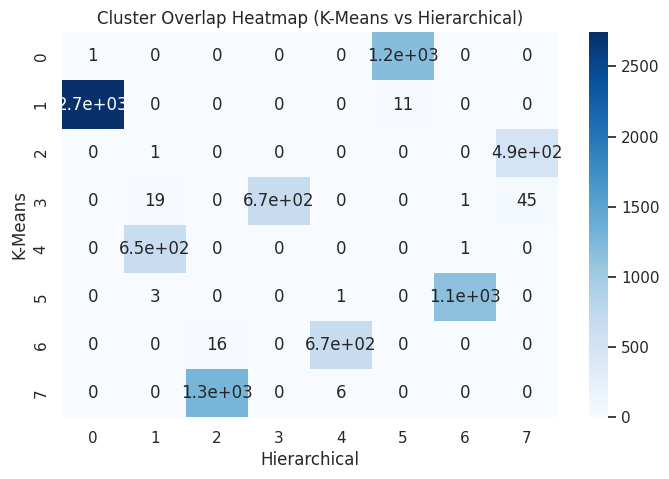

In [958]:
plt.figure(figsize=(8,5))
sns.heatmap(comparison, annot=True, cmap="Blues")
plt.title("Cluster Overlap Heatmap (K-Means vs Hierarchical)")
plt.xlabel("Hierarchical")
plt.ylabel("K-Means")
plt.show()
